## Task 1: Setting the Baseline

In ML, it is essential to establish a baseline model for comparison with any developments.

### Task 1.1 Data Preparation and Validation Pipeline

- First, explore the training data for any anomalies and visualize some trajectories. Each trajectory consists of 258 lines, one per data point. Note that after a collision, all lines of that trajectory will be zero up to the 258th data point for that trajectory.

Necessary imports

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression, RidgeCV, MultiTaskLassoCV
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils import resample
from skl2onnx import convert_sklearn
from skl2onnx.common.data_types import FloatTensorType
import seaborn as sns
from sklearn.neighbors import KNeighborsRegressor

Load dataset from CSV file and analyze it in terms of missing values and dataset summary

In [2]:
df = pd.read_csv('../mlNOVA/X_train.csv')
df.drop(columns=['v_x_1','v_y_1','v_x_2','v_y_2','v_x_3','v_y_3'], inplace=True) # Velocities don't seem to help
df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,Id
0,0.000000,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,0
1,0.039062,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1
2,0.078125,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,2
3,0.117188,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,3
4,0.156250,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,4


Dataframe should have the data grouped by scenarios

In [3]:
# got this code from https://stackoverflow.com/questions/17315737/split-a-large-pandas-dataframe or https://www.statology.org/pandas-chunk-dataframe/
SUBFRAME_SIZE = 257

def fixed_size_subframes(data, n):
    return [data[i : i + n].copy() for i in range(0, data.shape[0], n)]

subframes = fixed_size_subframes(df, SUBFRAME_SIZE)

Visualize trajectories

In [4]:
# k = np.random.randint(len(subframes))

#ks = [2, 5, 284, 315, 317, 338, 4643] # some scenarios with collisions
#ks = range(10)
ks = []

for k in ks:
    subframe = subframes[k]
    first_row = subframe.iloc[0]
    
    print(k)
    plt.figure()

    plt.plot(subframe.x_1, subframe.y_1)
    plt.plot(subframe.x_2, subframe.y_2)
    plt.plot(subframe.x_3, subframe.y_3)

    plt.plot(first_row.x_1, first_row.y_1, 's', label='Body 1')
    plt.plot(first_row.x_2, first_row.y_2, 's', label='Body 2')
    plt.plot(first_row.x_3, first_row.y_3, 's', label='Body 3')
    
    plt.legend()
    plt.title(f'Scenario {k}')
    plt.xlabel('X')
    plt.ylabel('Y')
    
    plt.show()

In [4]:
def remove_useless_rows(subframes):
    cleaned_subframes = []
    
    for df in subframes:
        # Identify rows where all values except for 'Id' are 0
        mask = (df.drop(columns=['Id']) != 0).any(axis=1)
        
        # Filter out the "useless" rows
        cleaned_df = df[mask]
        
        # Append the cleaned dataframe to the list
        if not cleaned_df.empty:
            cleaned_subframes.append(cleaned_df)
    
    return cleaned_subframes

# Assuming 'subframes' is your list of dataframes, each representing a simulation
subframes = remove_useless_rows(subframes)

Delete scenarios who would induce a collision, as these are anomalies

Create features and target matrices from the grouped data

Features and target matrices should have information grouped by scenario

In [5]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

X_chunks, y_chunks = create_features_and_targets(subframes, ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

Split dataset into training (80%), validation (10%) and test (10%) sets.

In [6]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

          t  x_1  y_1       x_2       y_2       x_3       y_3
0  0.000000  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689
1  0.039062  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689
2  0.078125  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689
3  0.117188  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689
4  0.156250  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689
             x_1       y_1       x_2       y_2       x_3       y_3
446923  1.000000  0.000000 -0.264968  0.411689 -0.735032 -0.411689
446924  0.999356  0.000078 -0.264979  0.410818 -0.734377 -0.410896
446925  0.997424  0.000312 -0.265015  0.408199 -0.732409 -0.408511
446926  0.994196  0.000701 -0.265082  0.403818 -0.729114 -0.404520
446927  0.989662  0.001245 -0.265192  0.397647 -0.724470 -0.398892


Concatenate the list of DataFrames into single DataFrames for X and y

In [7]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

# KNN

In [37]:
polyreg=make_pipeline(StandardScaler(), KNeighborsRegressor(n_neighbors=5))

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

## Task 1.2 Learn the baseline model


Linear regression model

In [8]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

Plot the y-y hat and present the RMSE in the validation set

In [9]:
def plot_y_yhat(y_test, y_pred, plot_title = "plot"):
    labels = ['x_1','y_1','x_2','y_2','x_3','y_3']
    MAX = 500
    if len(y_test) > MAX:
        idx = np.random.choice(len(y_test),MAX, replace=False)
    else:
        idx = np.arange(len(y_test))
    plt.figure(figsize=(10,10))
    for i in range(6):
        x0 = np.min(y_test[idx,i])
        x1 = np.max(y_test[idx,i])
        plt.subplot(3,2,i+1)
        plt.scatter(y_test[idx,i],y_pred[idx,i])
        plt.xlabel('True '+labels[i])
        plt.ylabel('Predicted '+labels[i])
        plt.plot([x0,x1],[x0,x1],color='red')
        plt.axis('square')
    plt.savefig(plot_title+'.pdf')
    plt.show()

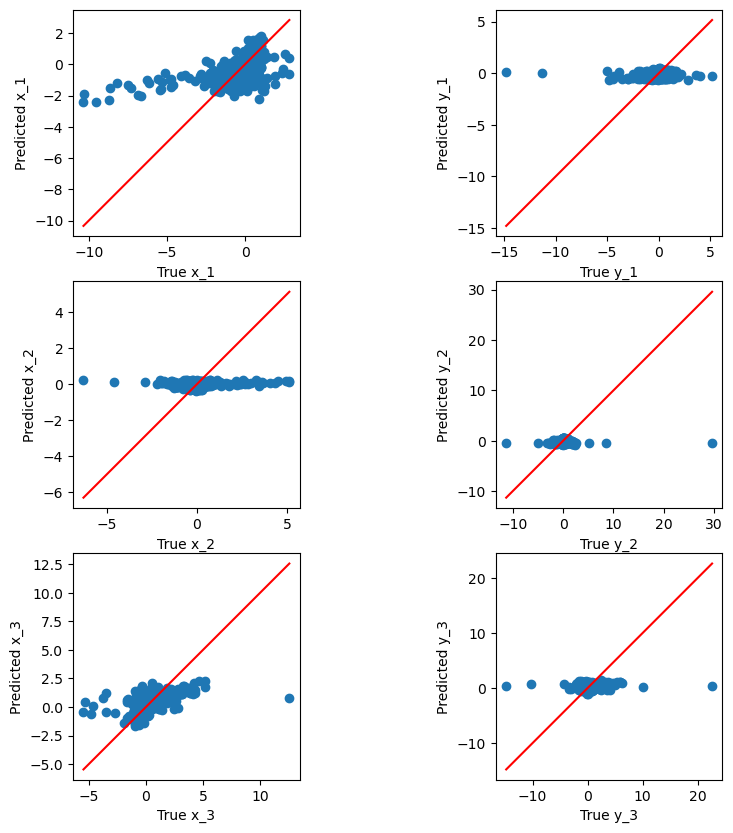

Validation RMSE: 1.3766263338318403


In [10]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

RMSE on the test set

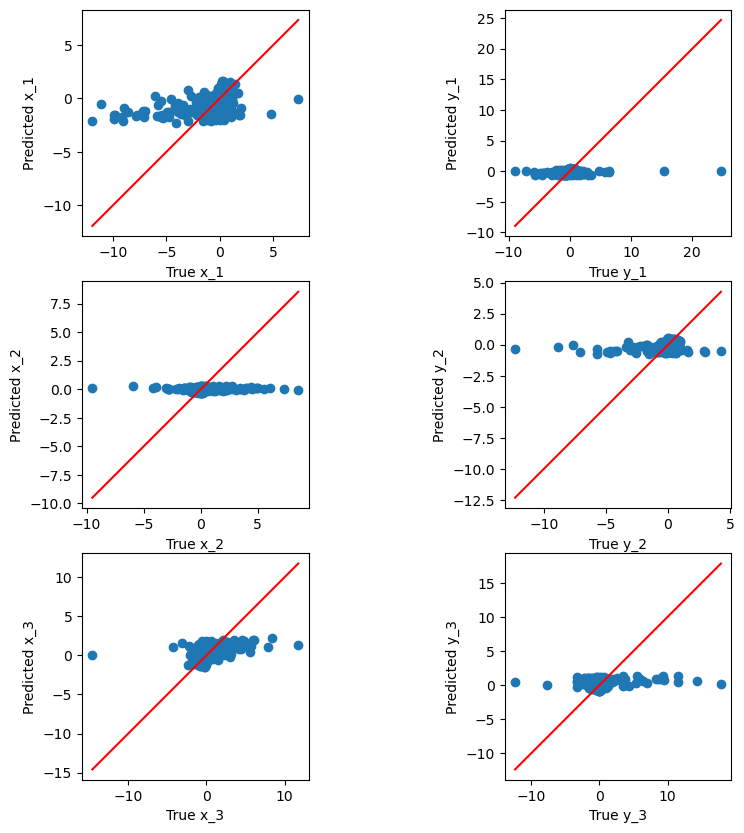

Test RMSE: 1.4524761254499114


In [11]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

Dataframe containing X_tests' info for submissions. Function to save model output into csv file ready for submission

In [6]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

In [7]:
def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])
    
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions['Id'] = df_positions.index
    
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions.to_csv(path, index=False)

Regarding the baseline model for submission of task 1.2

In [46]:
y_baseline_pred = polyreg.predict(X_kaggle_df)

save_predictions(y_baseline_pred, '../submissions/baseline_model.csv')

In [40]:
y_baseline_pred = polyreg.predict(X_kaggle_df)

save_predictions(y_baseline_pred, '../submissions/knn_submission.csv')

# Task 2: Nonlinear models on the data — the Polynomial model

## Task 2.1 Development

In [8]:
def validate_poly_regression(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9), max_features=None):
    best_rmse = np.inf
    best_model = None
    best_degree = None

    for degree in degrees:
        
        poly = PolynomialFeatures(degree, include_bias=False)
        
        # Default to Linear Regression if no regressor is specified
        if regressor is None:
            polyreg = make_pipeline(StandardScaler(), poly, LinearRegression())
        else:
            polyreg = make_pipeline(StandardScaler(), poly, regressor)
            
        polyreg.fit(X_train, y_train)
        
        n_features = poly.n_output_features_
        
        # Abort if number of features exceeds the limit
        if max_features is not None and n_features > max_features:
            break
            
        y_pred = polyreg.predict(X_val)
        
        rmse = root_mean_squared_error(y_val, y_pred)
        
        print(f"Degree {degree}: {n_features} features | RMSE: {rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = polyreg
            best_degree = degree
            
    print(f"Best Degree: {best_degree}, RMSE: {best_rmse}")
    
    return best_model, best_degree, best_rmse


In [ ]:
model, degree, rmse = validate_poly_regression(X_train_df, y_train_df, X_dev_df, y_dev_df, degrees=range(1, 6), regressor=MultiTaskLassoCV())

Degree 1: 7 features | RMSE: 1.37661951042865
Degree 2: 35 features | RMSE: 1.3514229413191245


Track degrees and RMSEs over multiple runs

Degree 1: 7 features | RMSE: 1.378557139877941
Degree 2: 35 features | RMSE: 1.3581064278009756
Degree 3: 119 features | RMSE: 1.3319776241525019
Degree 4: 329 features | RMSE: 1.3378447027675522
Degree 5: 791 features | RMSE: 1.4159826754842844
Degree 6: 1715 features | RMSE: 1.3405481474829557
Degree 7: 3431 features | RMSE: 1.4031668842027927
Degree 8: 6434 features | RMSE: 1.2912258812255304
Best Degree: 8, RMSE: 1.2912258812255304
Degree 1: 7 features | RMSE: 1.3774249583414881
Degree 2: 35 features | RMSE: 1.3544634374049174
Degree 3: 119 features | RMSE: 1.3237045566287895
Degree 4: 329 features | RMSE: 1.3244611714602053
Degree 5: 791 features | RMSE: 1.4128820547568053
Degree 6: 1715 features | RMSE: 1.3197566822765106
Degree 7: 3431 features | RMSE: 1.5420611354952982
Degree 8: 6434 features | RMSE: 1.5639518740406464
Best Degree: 6, RMSE: 1.3197566822765106
Degree 1: 7 features | RMSE: 1.3768616773637496
Degree 2: 35 features | RMSE: 1.3520296427850764
Degree 3: 119 features

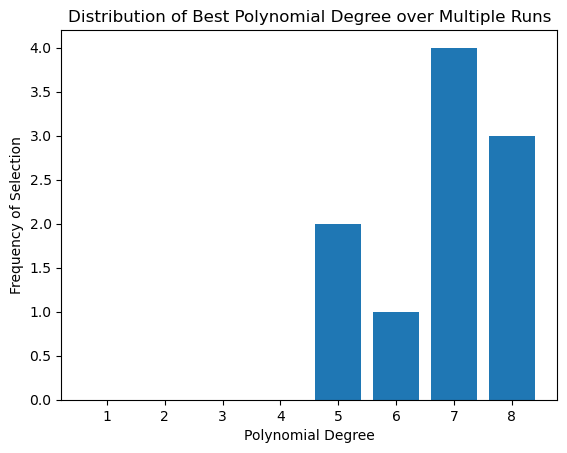

In [45]:
degree_counts = {degree: 0 for degree in range(1, 9)}

for run in range(10):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, degrees=range(1, 9))
    
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

Degree 1: 7 features | RMSE: 1.3774902194255192
Degree 2: 35 features | RMSE: 1.3523301999079875
Degree 3: 119 features | RMSE: 1.3145768990463087
Degree 4: 329 features | RMSE: 1.2800654395856654
Degree 5: 791 features | RMSE: 1.2634528712269226
Degree 6: 1715 features | RMSE: 1.2417129494994643
Degree 7: 3431 features | RMSE: 1.2240821424980999
Degree 8: 6434 features | RMSE: 1.2187381125891656
Best Degree: 8, RMSE: 1.2187381125891656
Degree 1: 7 features | RMSE: 1.3764072539796723
Degree 2: 35 features | RMSE: 1.3517299704937706
Degree 3: 119 features | RMSE: 1.3140473032710935
Degree 4: 329 features | RMSE: 1.2812897019429113
Degree 5: 791 features | RMSE: 1.2660766770857295
Degree 6: 1715 features | RMSE: 1.2466050229359356
Degree 7: 3431 features | RMSE: 1.2274192448791788
Degree 8: 6434 features | RMSE: 1.218382368983165
Best Degree: 8, RMSE: 1.218382368983165
Degree 1: 7 features | RMSE: 1.3769549421282745
Degree 2: 35 features | RMSE: 1.3525662891466717
Degree 3: 119 features 

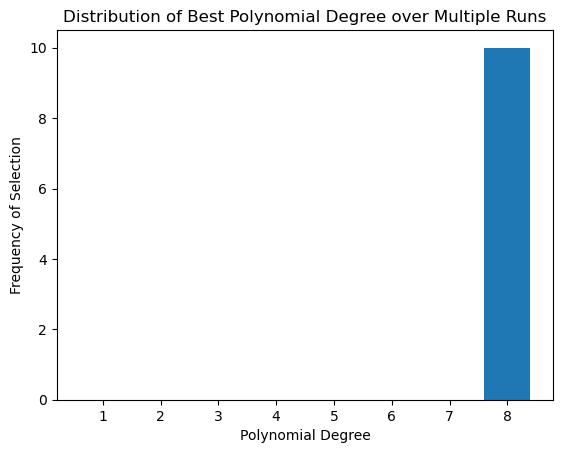

In [46]:
degree_counts = {degree: 0 for degree in range(1,9)}

for run in range(10):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, regressor = RidgeCV(), degrees=range(1, 9))
    
    # Track the best degree for this run
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

## Task 2.2 Evaluation

### Evaluate your new nonlinear model against your baseline. Compare RMSE and the y-y hat plots. 

8 was the best performing degree of polynomial in linear regression. But given the size of the training data used to train the model, there is not enough memory to fit it to a 8th degree polynomial regression. The best we could do is degree 7, which as shown by the histogram above, is one of the contenders for best model.

In [49]:
degree=7

polyreg = make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('polynomialfeatures',
                 PolynomialFeatures(degree=7, include_bias=False)),
                ('linearregression', LinearRegression())])

Plot y-y hat in validation set and present RMSE

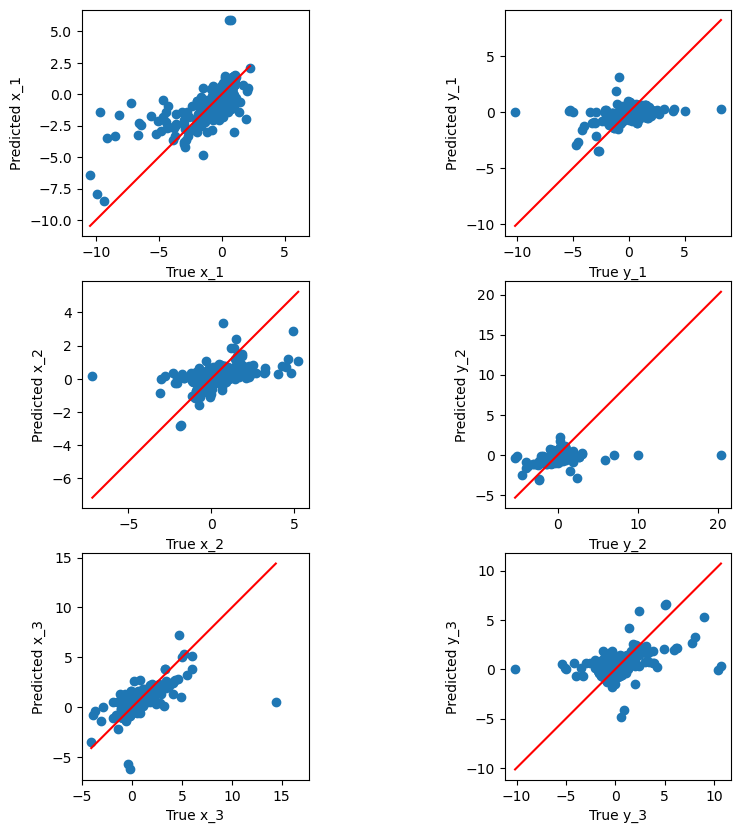

Validation RMSE: 1.2372732161464846


In [50]:
y_dev_pred = polyreg.predict(X_dev_df)

plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

RMSE in the test set

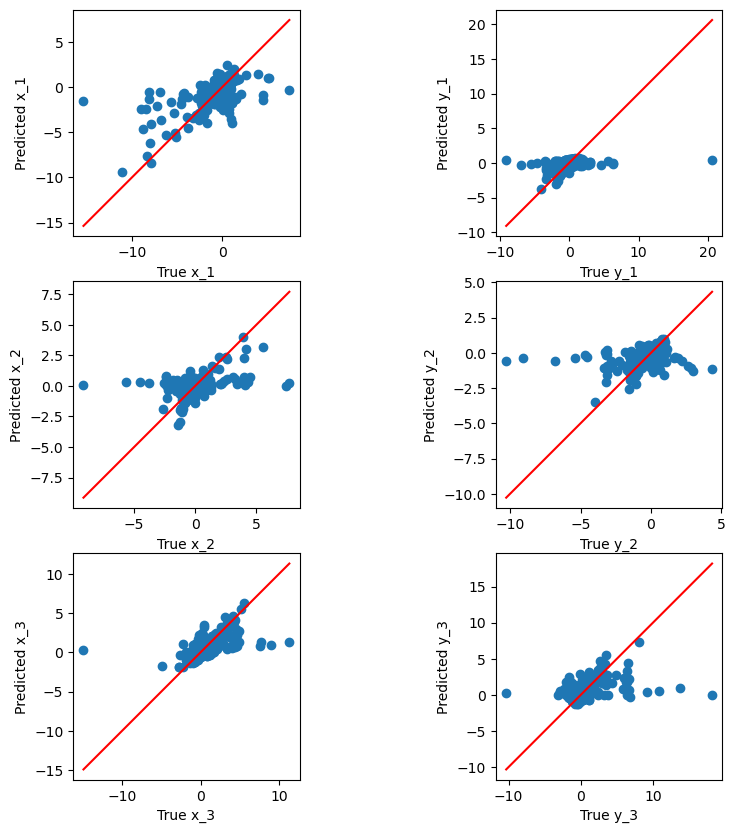

Test RMSE: 1.2758654959318019


In [52]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

Regarding the polynomial model for submission of task 2.2

In [74]:
y_polynomial_pred = polyreg.predict(X_kaggle_df)

save_predictions(y_polynomial_pred, '../submissions/polynomial_submission.csv')

Try out RidgeCV and the best degree was 8

In [71]:
degree = 6

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

In [75]:
print(type(polyreg))
initial_type = [('float_input', FloatTensorType([None, X_kaggle_df.shape[1]]))]  

# Convert the model to ONNX format
onnx_model = convert_sklearn(polyreg, initial_types=initial_type)

# Save the ONNX model to a file
with open("baseline-model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

<class 'sklearn.pipeline.Pipeline'>


RMSE in validation set for RidgeCV

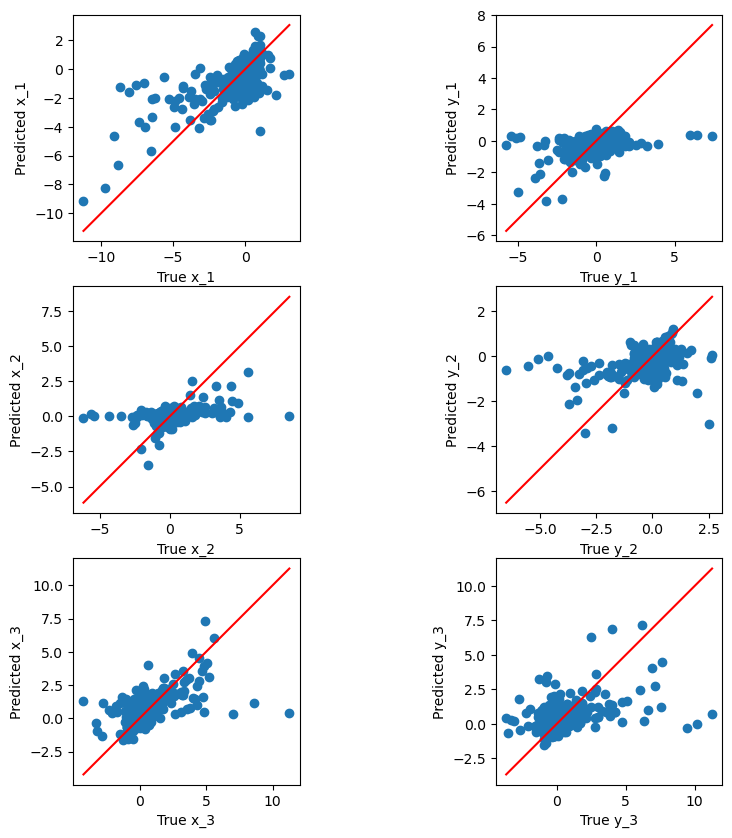

Validation RMSE: 1.2394613366013878


In [72]:
y_dev_pred = polyreg.predict(X_dev_df)

plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

RMSE in test set for RidgeCV

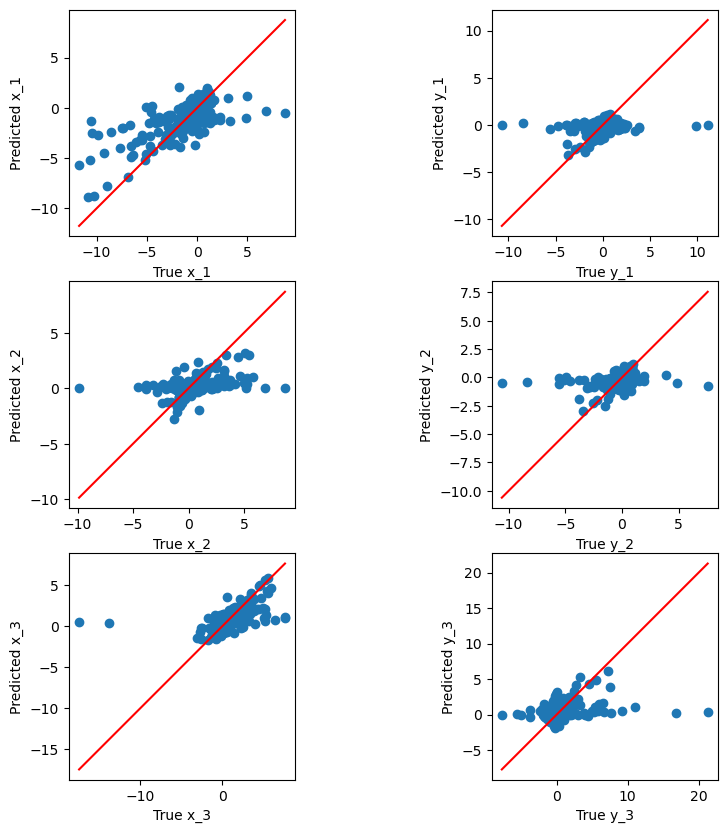

Test RMSE: 1.2953546394428888


In [73]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

# Task 3: Feature Engineering

## Task 3.1 Removing variables

Explore the features and verify if there are any linear relationships between them. 

Remember, features should be uncorrelated with each other and highly correlated with the target variables. Use the Seaborn package to inspect these relationships.

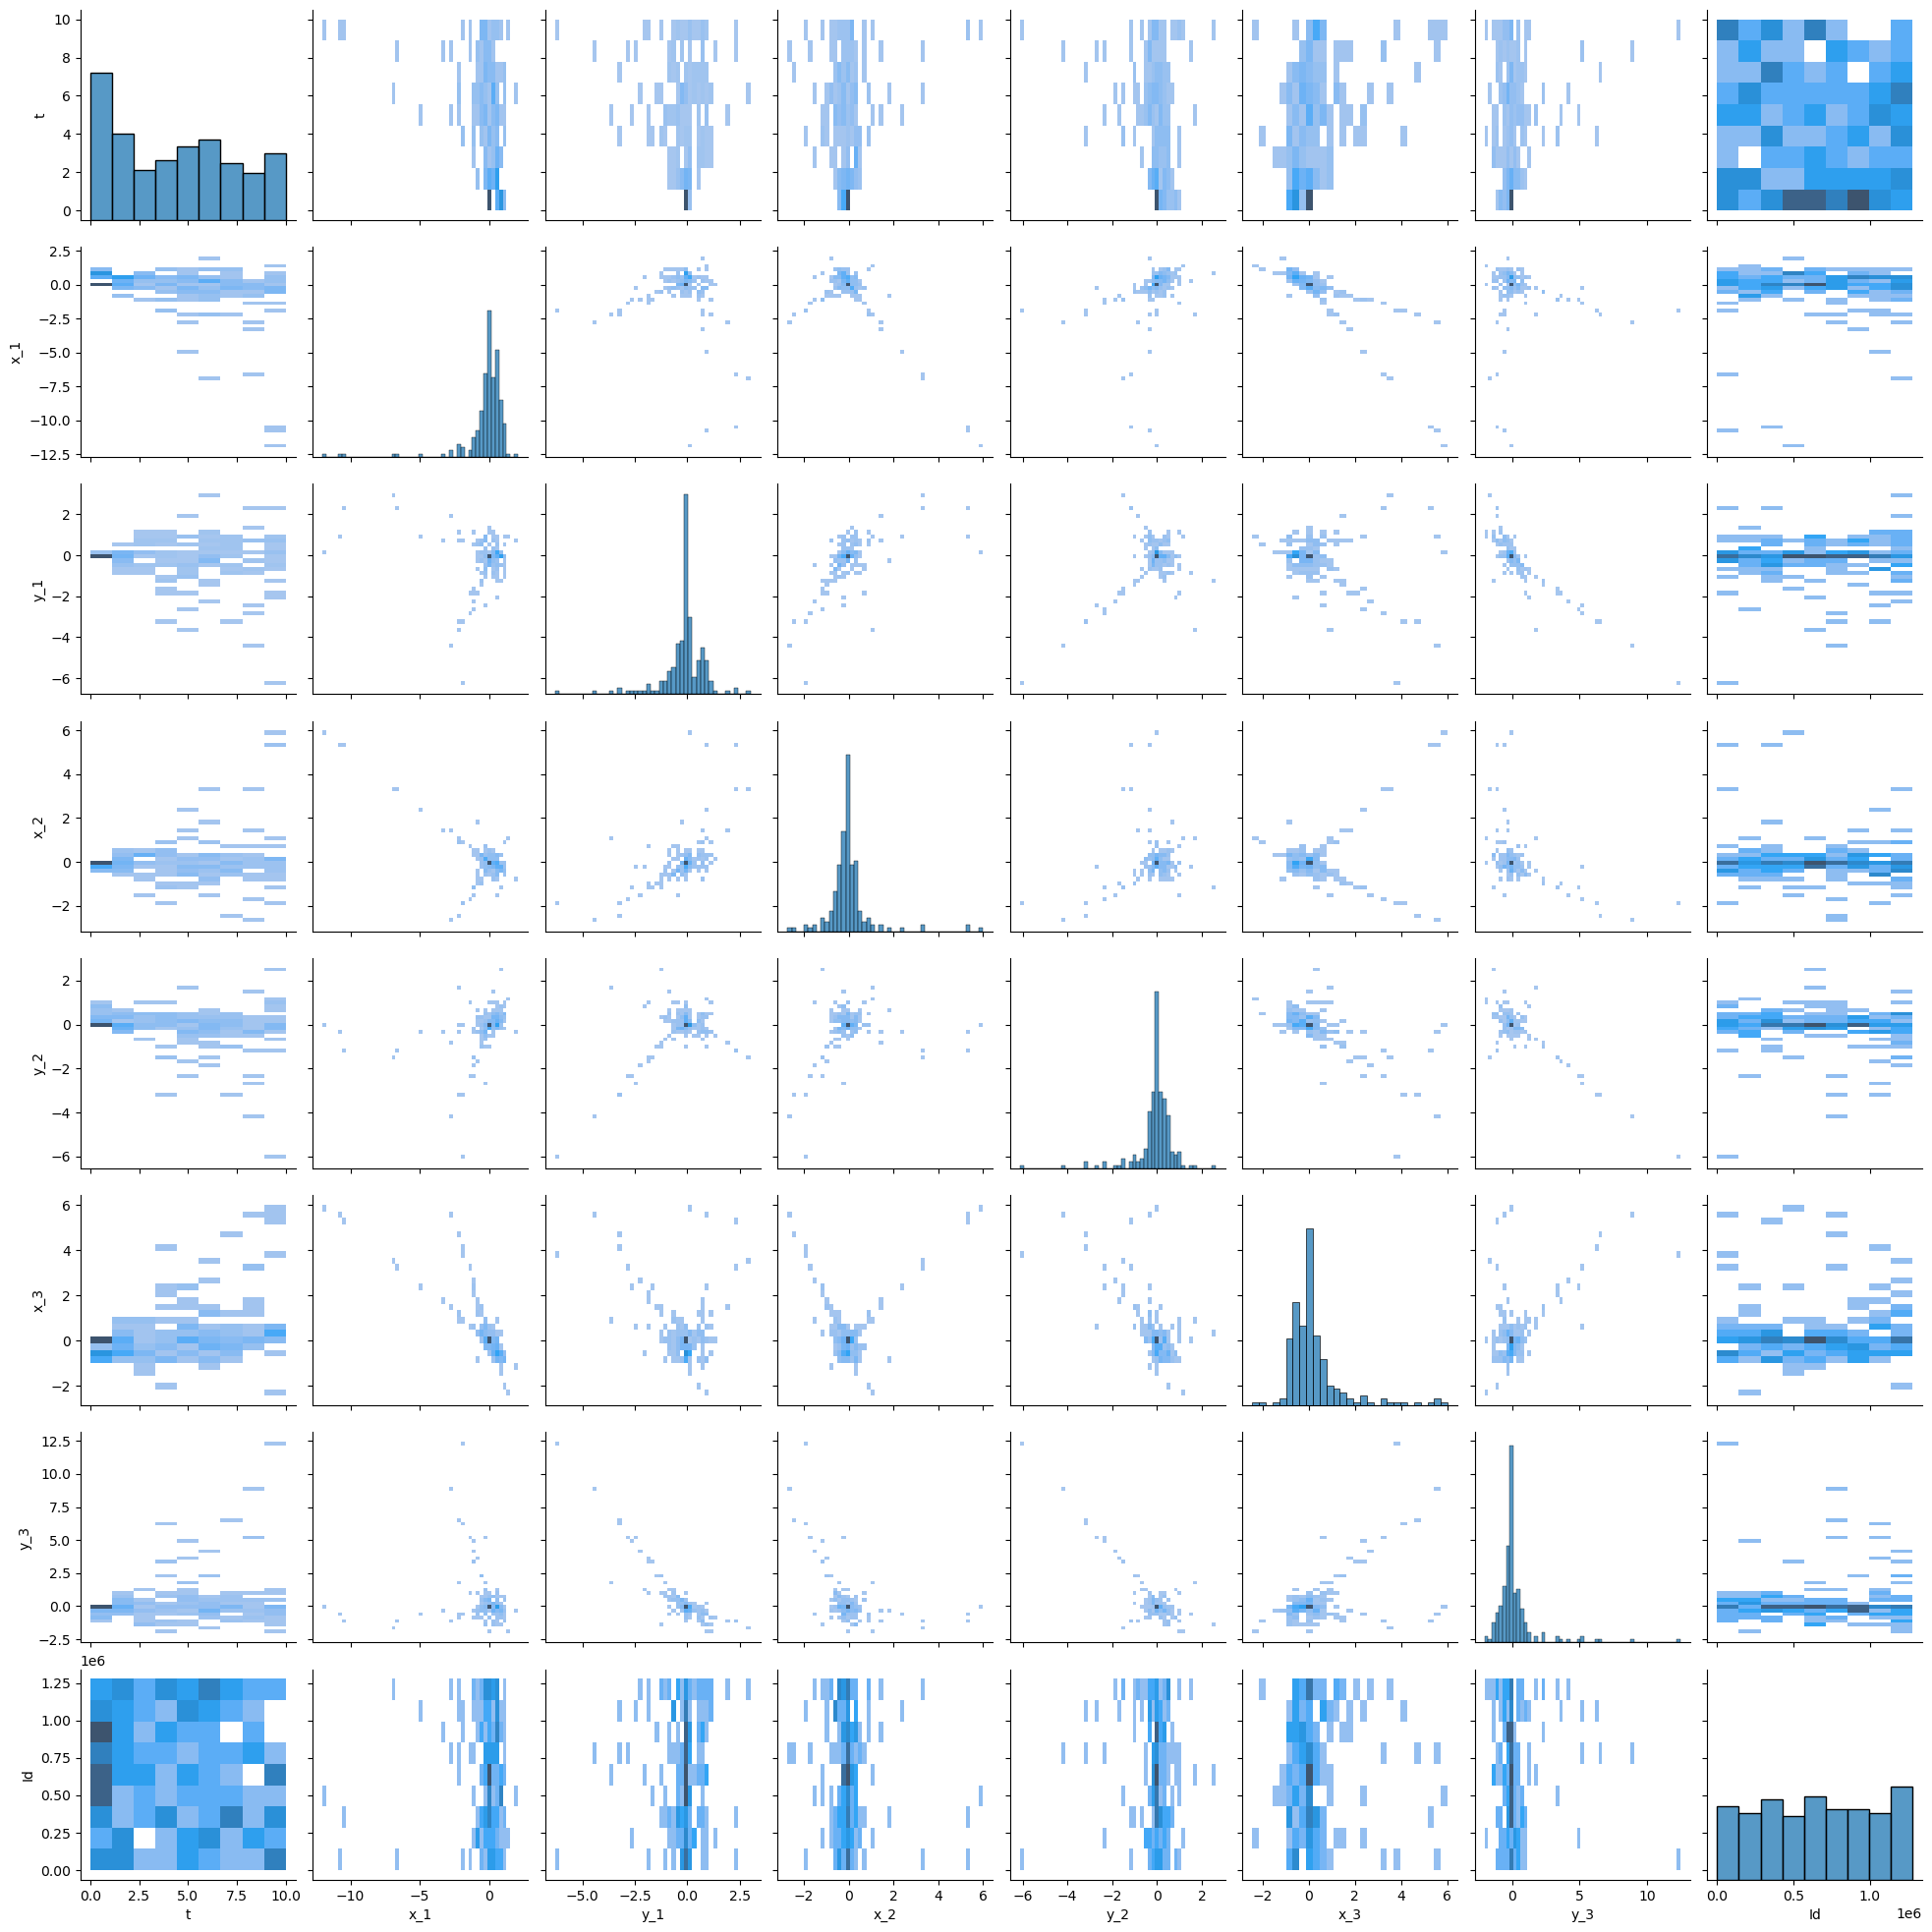

In [61]:
sns.pairplot(df.sample(200), kind="hist")

<Axes: >

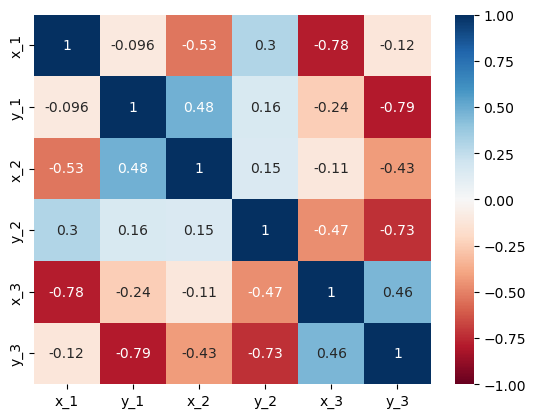

In [68]:
df_no_id_t = df.drop(columns=['t','Id'])
corr = df_no_id_t.corr()
sns.heatmap(corr, annot=True, cmap='RdBu', vmin = -1, vmax = 1)

<Axes: >

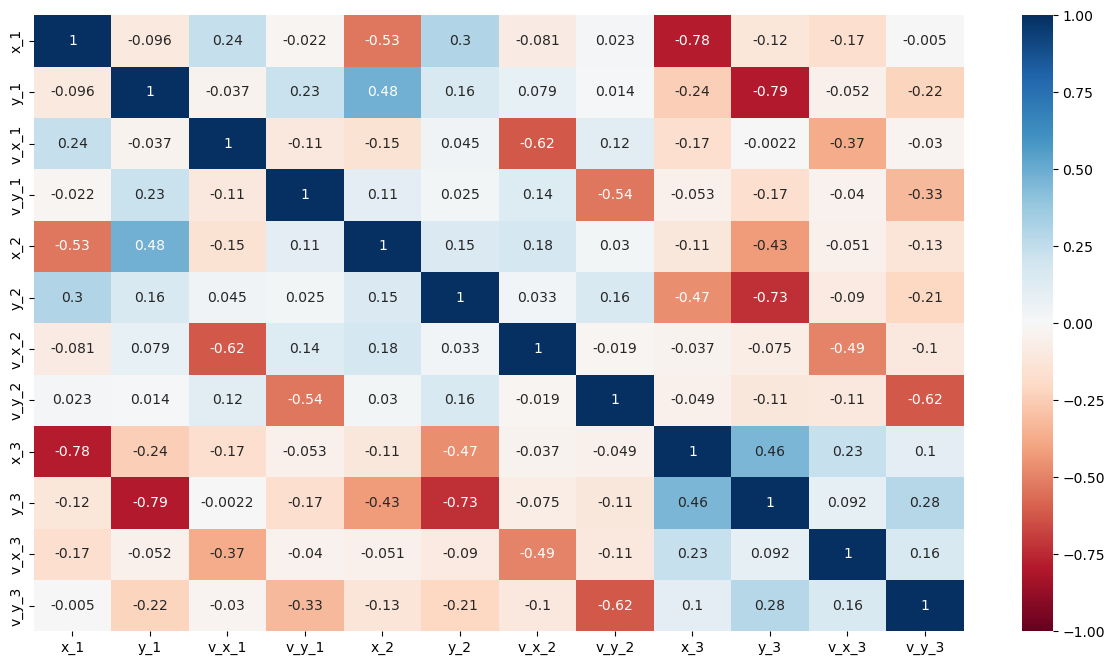

In [70]:
df_with_v = pd.read_csv('../mlNOVA/X_train.csv')
df_v_no_id_t = df_with_v.drop(columns=['t','Id'])
corr = df_v_no_id_t.corr()

plt.figure(figsize=(15,8))
sns.heatmap(corr, annot=True, cmap='RdBu', vmin = -1, vmax = 1)

### Eliminating y_3 as a feature

In [13]:
subframes = fixed_size_subframes(df, SUBFRAME_SIZE)

In [14]:
subframes = remove_useless_rows(subframes)
len(subframes)

4998

In [15]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

X_chunks, y_chunks = create_features_and_targets(subframes, ['y_1', 'x_2', 'y_2', 'x_3'], ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [16]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [17]:
X_train[0].head()

,t,y_1,x_2,y_2,x_3
0,0.000000,0.0,-0.264968,0.411689,-0.735032
1,0.039062,0.0,-0.264968,0.411689,-0.735032
2,0.078125,0.0,-0.264968,0.411689,-0.735032
3,0.117188,0.0,-0.264968,0.411689,-0.735032
4,0.156250,0.0,-0.264968,0.411689,-0.735032


In [87]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

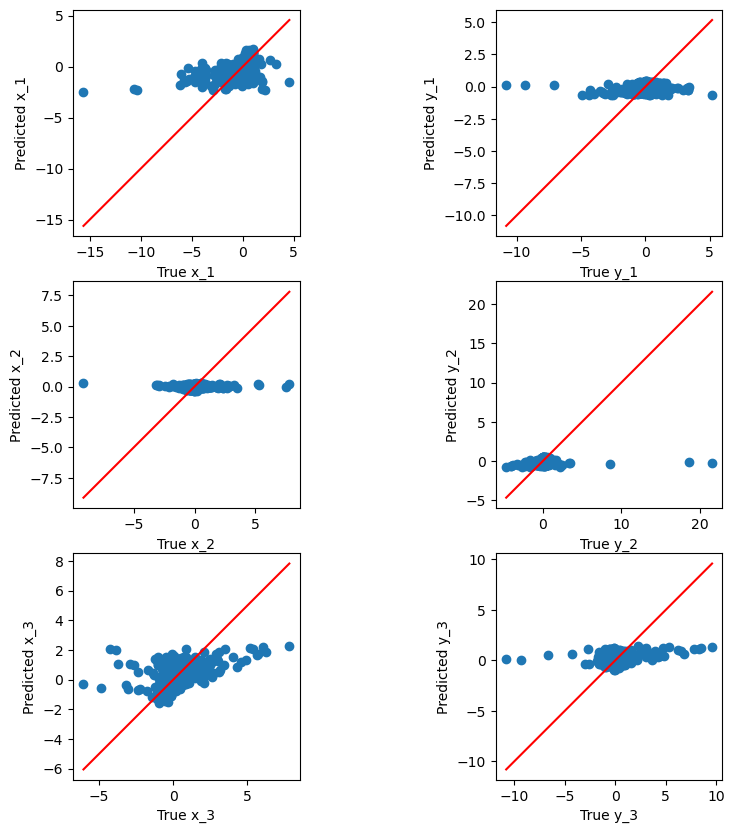

Validation RMSE: 1.376639320949387


In [88]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

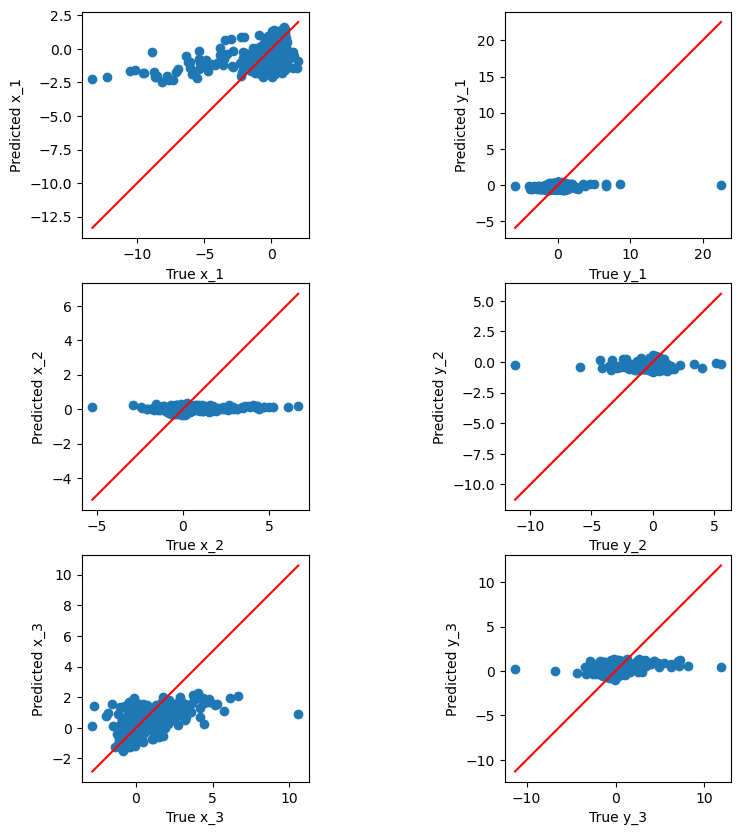

Test RMSE: 1.4524799295711415


In [89]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

### Eliminating x_1 as a feature

In [8]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

X_chunks, y_chunks = create_features_and_targets(subframes, ['y_1', 'x_2', 'y_2', 'x_3'], ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [9]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [22]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

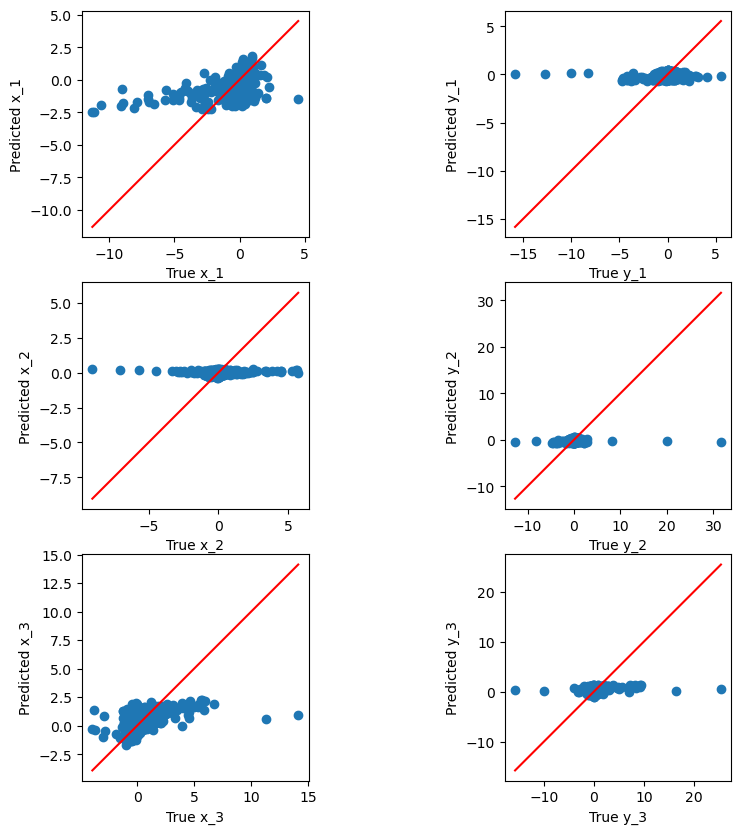

Validation RMSE: 1.3766261446822874


In [23]:
plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

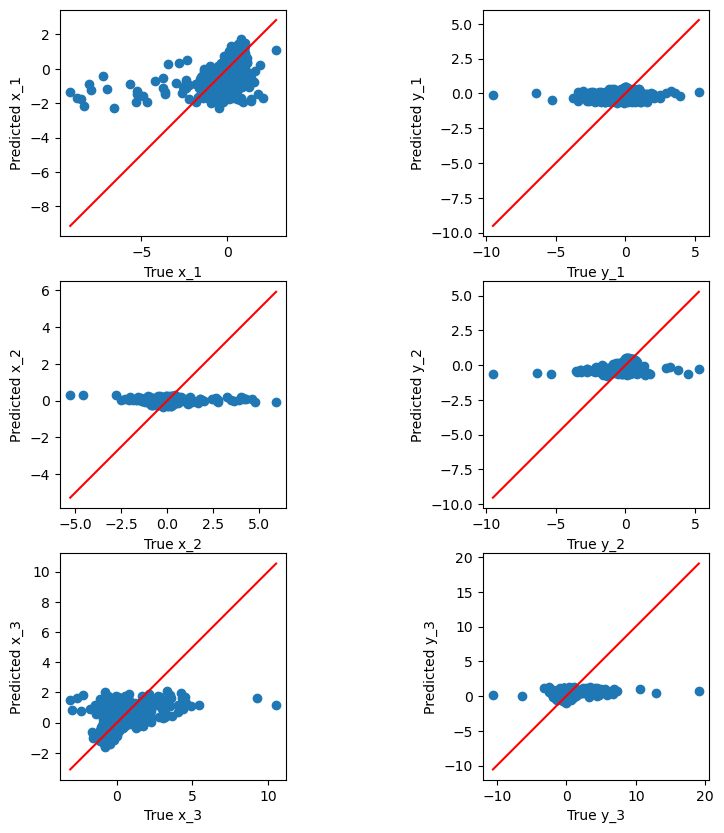

Test RMSE: 1.452475933574193


In [24]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

In [22]:
X_kaggle_df = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df.drop(columns=['Id'], inplace=True)

X_kaggle_df_No_Y_3_X_1 = X_kaggle_df.drop(columns=['x_1', 'y_3'])
X_kaggle_df_No_Y_3_X_1.head()

,t,y_1,x_2,y_2,x_3
0,0.000000,0.0,-0.179617,0.730085,-0.820383
1,0.039062,0.0,-0.179617,0.730085,-0.820383
2,0.078125,0.0,-0.179617,0.730085,-0.820383
3,0.117188,0.0,-0.179617,0.730085,-0.820383
4,0.156250,0.0,-0.179617,0.730085,-0.820383


In [26]:
y_baseline_pred = polyreg.predict(X_kaggle_df_No_Y_3_X_1)

save_predictions(y_baseline_pred, '../submissions/baseline_model.csv')

with ridge cv, degree 6

In [11]:
degree = 9

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

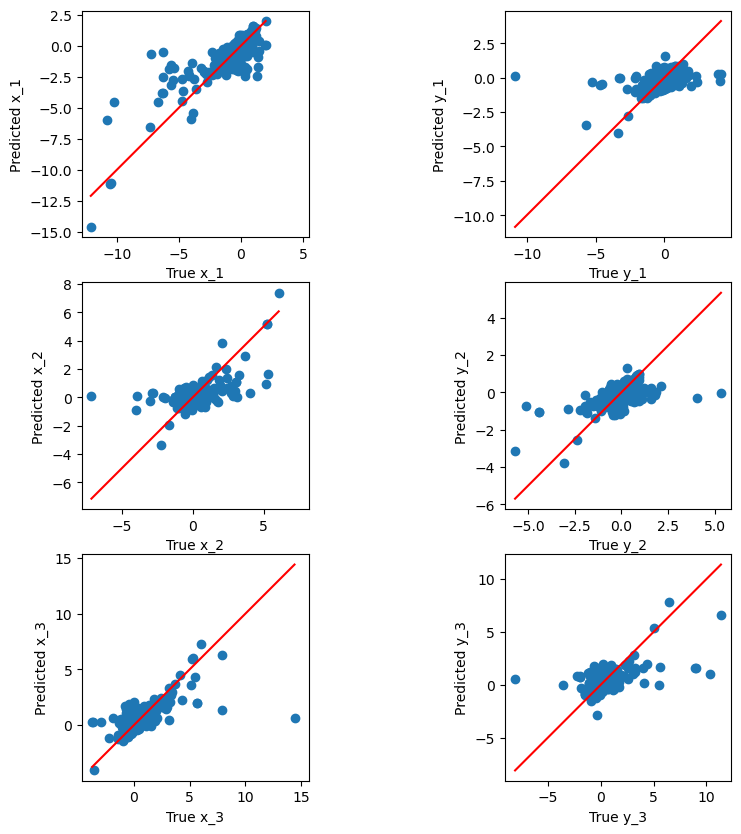

Validation RMSE: 1.1947012723593315


In [14]:
y_dev_pred = polyreg.predict(X_dev_df)

plot_y_yhat(y_dev_df.values, y_dev_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_df, y_dev_pred)

print(f"Validation RMSE: {rmse}")

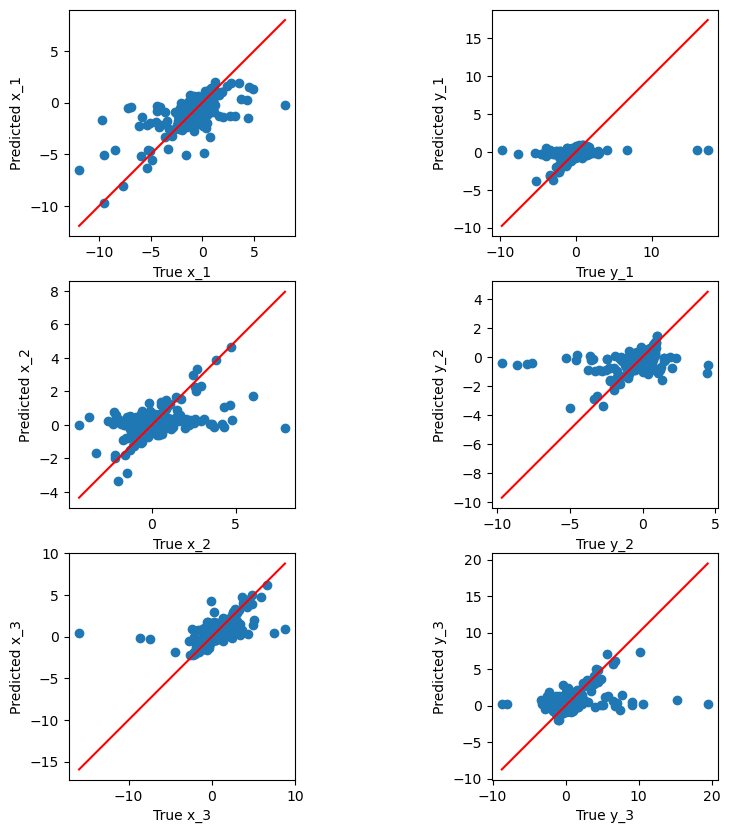

Test RMSE: 1.250186092171629


In [15]:
y_test_pred = polyreg.predict(X_test_df)

plot_y_yhat(y_test_df.values, y_test_pred, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_df, y_test_pred)

print(f"Test RMSE: {rmse}")

In [20]:
print(type(polyreg))
initial_type = [('float_input', FloatTensorType([None, 5]))]  

# Convert the model to ONNX format
onnx_model = convert_sklearn(polyreg, initial_types=initial_type)

# Save the ONNX model to a file
with open("ridgeCV_9th_degree_no_y_3_x_1.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

<class 'sklearn.pipeline.Pipeline'>


In [23]:
y_reduced_polynomial_pred = polyreg.predict(X_kaggle_df_No_Y_3_X_1)

save_predictions(y_reduced_polynomial_pred, '../submissions/reduced_polynomial_submission.csv')

Degree 1: 5 features | RMSE: 1.3768652571096862
Degree 2: 20 features | RMSE: 1.3520828417217157
Degree 3: 55 features | RMSE: 1.3199355354320803
Degree 4: 125 features | RMSE: 1.4066091289026268
Degree 5: 251 features | RMSE: 1.30627875199483
Degree 6: 461 features | RMSE: 1.3318540283829983
Degree 7: 791 features | RMSE: 1.2499575046867117
Degree 8: 1286 features | RMSE: 1.2569255240335855
Degree 9: 2001 features | RMSE: 1.2507942320193464
Best Degree: 7, RMSE: 1.2499575046867117
Degree 1: 5 features | RMSE: 1.3782097145258287
Degree 2: 20 features | RMSE: 1.35457450422898
Degree 3: 55 features | RMSE: 1.3274549119245853
Degree 4: 125 features | RMSE: 1.3119431527091072
Degree 5: 251 features | RMSE: 1.5525859310318448
Degree 6: 461 features | RMSE: 1.388356616936754
Degree 7: 791 features | RMSE: 1.3612699377405908
Degree 8: 1286 features | RMSE: 1.489000009396319
Degree 9: 2001 features | RMSE: 1.3479020136726614
Best Degree: 4, RMSE: 1.3119431527091072
Degree 1: 5 features | RMSE:

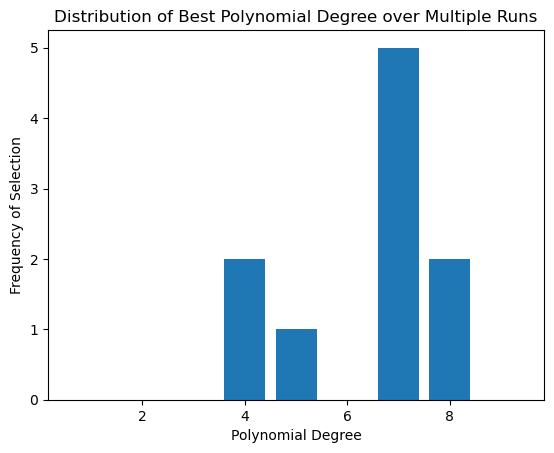

In [30]:
degree_counts = {degree: 0 for degree in range(1, 10)}

for run in range(10):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, degrees=range(1, 10))
    
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

Degree 1: 5 features | RMSE: 1.3755870312188607
Degree 2: 20 features | RMSE: 1.3509514474396311
Degree 3: 55 features | RMSE: 1.3132992335733034
Degree 4: 125 features | RMSE: 1.2811036329260614
Degree 5: 251 features | RMSE: 1.2670653558622056
Degree 6: 461 features | RMSE: 1.2490451600405388
Degree 7: 791 features | RMSE: 1.2293359209874621
Degree 8: 1286 features | RMSE: 1.2184027700957192
Degree 9: 2001 features | RMSE: 1.2152936709836812
Best Degree: 9, RMSE: 1.2152936709836812
Degree 1: 5 features | RMSE: 1.3774309053695095
Degree 2: 20 features | RMSE: 1.3531360265185597
Degree 3: 55 features | RMSE: 1.316060887029798
Degree 4: 125 features | RMSE: 1.2811719330487554
Degree 5: 251 features | RMSE: 1.2637355402475297
Degree 6: 461 features | RMSE: 1.2447301857023085
Degree 7: 791 features | RMSE: 1.223010972188342
Degree 8: 1286 features | RMSE: 1.2134558285895938
Degree 9: 2001 features | RMSE: 1.207708320317319
Best Degree: 9, RMSE: 1.207708320317319
Degree 1: 5 features | RMS

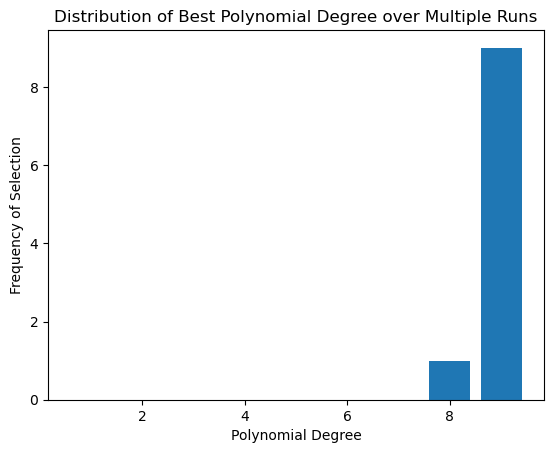

In [31]:
degree_counts = {degree: 0 for degree in range(1,10)}

for run in range(10):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, regressor = RidgeCV(), degrees=range(1, 10))
    
    # Track the best degree for this run
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()

## Task 3.3 Adding Variables

### Adding euclidian distance between each pair of points

In [5]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
        X_chunk_df['dist_12'] = np.sqrt((X_chunk_df['x_2'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_2'] - X_chunk_df['y_1'])**2)
        X_chunk_df['dist_23'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_2'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_2'])**2)
        X_chunk_df['dist_13'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_1'])**2)
        
        # Extract targets using vectorized operations and calculate Euclidean distances for targets
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        y_chunk_df['dist_12'] = np.sqrt((y_chunk_df['x_2'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_2'] - y_chunk_df['y_1'])**2)
        y_chunk_df['dist_23'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_2'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_2'])**2)
        y_chunk_df['dist_13'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_1'])**2)
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

# Example usage:
X_chunks, y_chunks = create_features_and_targets(subframes, 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [6]:
print(X_chunks[0].head())
print(y_chunks[0].head())

          t  x_1  y_1       x_2       y_2       x_3       y_3   dist_12  \
0  0.000000  1.0  0.0 -0.266467  0.859196 -0.733533 -0.859196  1.530411   
1  0.039062  1.0  0.0 -0.266467  0.859196 -0.733533 -0.859196  1.530411   
2  0.078125  1.0  0.0 -0.266467  0.859196 -0.733533 -0.859196  1.530411   
3  0.117188  1.0  0.0 -0.266467  0.859196 -0.733533 -0.859196  1.530411   
4  0.156250  1.0  0.0 -0.266467  0.859196 -0.733533 -0.859196  1.530411   

    dist_23   dist_13  
0  1.780737  1.934775  
1  1.780737  1.934775  
2  1.780737  1.934775  
3  1.780737  1.934775  
4  1.780737  1.934775  
        x_1       y_1       x_2       y_2       x_3       y_3   dist_12  \
0  1.000000  0.000000 -0.266467  0.859196 -0.733533 -0.859196  1.530411   
1  0.999548  0.000092 -0.266261  0.858781 -0.733287 -0.858874  1.529581   
2  0.998190  0.000370 -0.265641  0.857535 -0.732549 -0.857905  1.527089   
3  0.995925  0.000833 -0.264606  0.855456 -0.731318 -0.856289  1.522931   
4  0.992747  0.001483 -0.26315

In [7]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

          t  x_1  y_1       x_2       y_2       x_3       y_3   dist_12  \
0  0.000000  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
1  0.039062  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
2  0.078125  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
3  0.117188  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
4  0.156250  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   

    dist_23   dist_13  
0  0.948108  1.783206  
1  0.948108  1.783206  
2  0.948108  1.783206  
3  0.948108  1.783206  
4  0.948108  1.783206  
             x_1       y_1       x_2       y_2       x_3       y_3   dist_12  \
446923  1.000000  0.000000 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
446924  0.999356  0.000078 -0.264979  0.410818 -0.734377 -0.410896  1.329380   
446925  0.997424  0.000312 -0.265015  0.408199 -0.732409 -0.408511  1.326696   
446926  0.994196  0.000701 -0.265082  0.403818 -0.729114 -0.404520  1.322226   
44692

In [8]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [10]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

In [13]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 2, 3, 4, 5]]
y_test_positions = y_test_df[position_columns].values

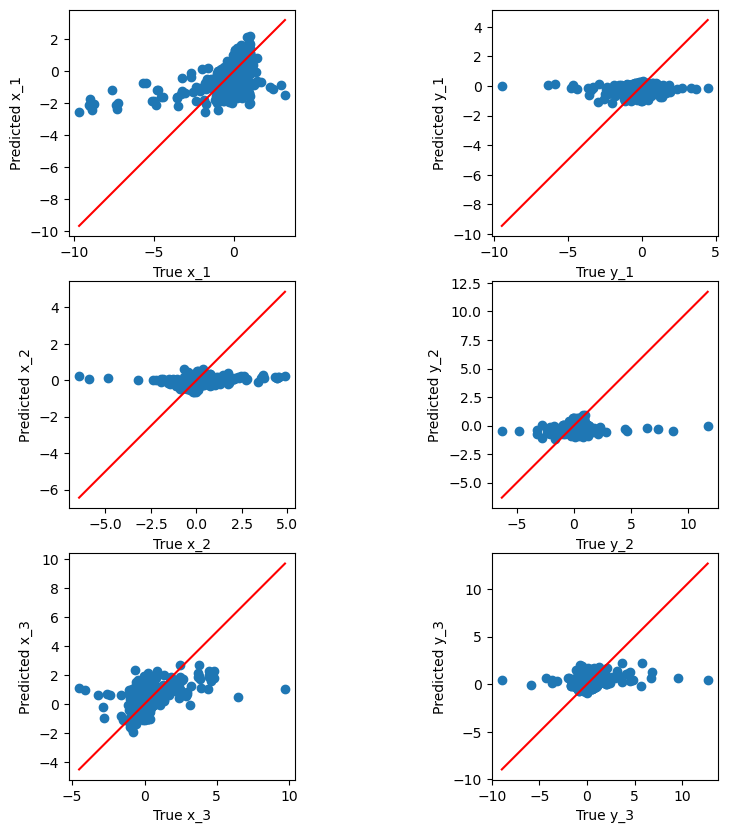

Validation RMSE: 1.354336181178171


In [18]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

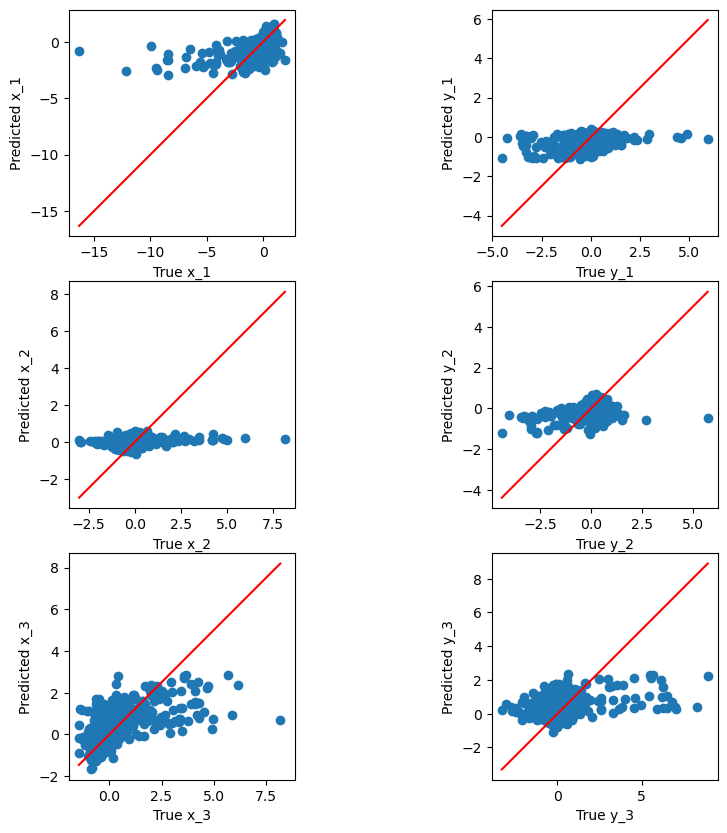

Test RMSE: 1.4415447440559497


In [19]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

### Adding angle between the points to the features

In [11]:
def calculate_angle(x1, y1, x2, y2, x3, y3):
    # Vector from (x1, y1) to (x2, y2)
    v1_x = x2 - x1
    v1_y = y2 - y1
    
    # Vector from (x1, y1) to (x3, y3)
    v2_x = x3 - x1
    v2_y = y3 - y1
    
    # Dot product between v1 and v2
    dot_product = v1_x * v2_x + v1_y * v2_y
    
    # Magnitude of v1 and v2
    magnitude_v1 = np.sqrt(v1_x**2 + v1_y**2)
    magnitude_v2 = np.sqrt(v2_x**2 + v2_y**2)
    
    # Compute the cosine of the angle (avoid division by zero)
    cos_theta = dot_product / (magnitude_v1 * magnitude_v2 + 1e-10)
    
    # Return the angle in radians using arccos
    return np.arccos(np.clip(cos_theta, -1, 1))  # Clipping to avoid floating point precision issues

In [49]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
        X_chunk_df['dist_12'] = np.sqrt((X_chunk_df['x_2'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_2'] - X_chunk_df['y_1'])**2)
        X_chunk_df['dist_23'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_2'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_2'])**2)
        X_chunk_df['dist_13'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_1'])**2)
        
        # Calculate the angles between the points
        X_chunk_df['angle_1'] = calculate_angle(X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_2'] = calculate_angle(X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_3'] = calculate_angle(X_chunk_df['x_3'], X_chunk_df['y_3'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'])
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe

        y_chunk_df['dist_12'] = np.sqrt((y_chunk_df['x_2'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_2'] - y_chunk_df['y_1'])**2)
        y_chunk_df['dist_23'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_2'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_2'])**2)
        y_chunk_df['dist_13'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_1'])**2)
        
        # Calculate angles for targets
        y_chunk_df['angle_1'] = calculate_angle(y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_2'] = calculate_angle(y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_3'] = calculate_angle(y_chunk_df['x_3'], y_chunk_df['y_3'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'])
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

In [50]:
X_chunks, y_chunks = create_features_and_targets(subframes, 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [51]:
y_chunks[0].head()

,x_1,y_1,x_2,y_2,x_3,y_3,dist_12,dist_23,dist_13,angle_1,angle_2,angle_3
0,1.000000,0.000000,-0.266467,0.859196,-0.733533,-0.859196,1.530411,1.780737,1.934775,1.056243,1.240093,0.845256
1,0.999548,0.000092,-0.266261,0.858781,-0.733287,-0.858874,1.529581,1.780015,1.934047,1.056264,1.240213,0.845115
2,0.998190,0.000370,-0.265641,0.857535,-0.732549,-0.857905,1.527089,1.777847,1.931863,1.056327,1.240575,0.844691
3,0.995925,0.000833,-0.264606,0.855456,-0.731318,-0.856289,1.522931,1.774230,1.928218,1.056431,1.241180,0.843981
4,0.992747,0.001483,-0.263154,0.852540,-0.729592,-0.854022,1.517098,1.769158,1.923107,1.056579,1.242035,0.842979


In [52]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

          t  x_1  y_1       x_2       y_2       x_3       y_3   dist_12  \
0  0.000000  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
1  0.039062  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
2  0.078125  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
3  0.117188  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
4  0.156250  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   

    dist_23   dist_13   angle_1   angle_2  angle_3  
0  0.948108  1.783206  0.547614  1.774899  0.81908  
1  0.948108  1.783206  0.547614  1.774899  0.81908  
2  0.948108  1.783206  0.547614  1.774899  0.81908  
3  0.948108  1.783206  0.547614  1.774899  0.81908  
4  0.948108  1.783206  0.547614  1.774899  0.81908  
             x_1       y_1       x_2       y_2       x_3       y_3   dist_12  \
446923  1.000000  0.000000 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
446924  0.999356  0.000078 -0.264979  0.410818 -0.734377 -0.410896  1.3

In [53]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [54]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

In [55]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 2, 3, 4, 5]]
y_test_positions = y_test_df[position_columns].values

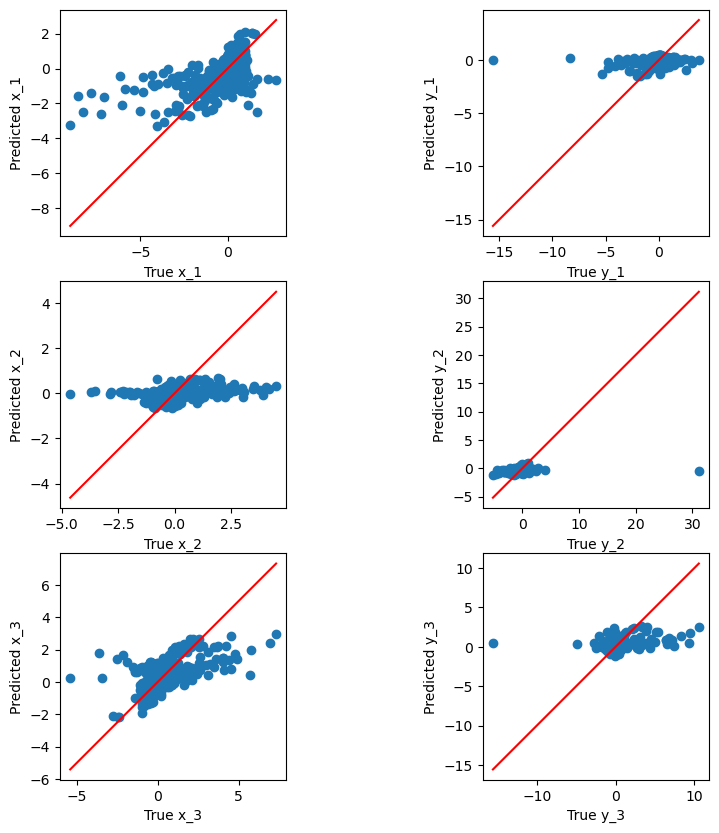

Validation RMSE: 1.3433694736190827


In [56]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

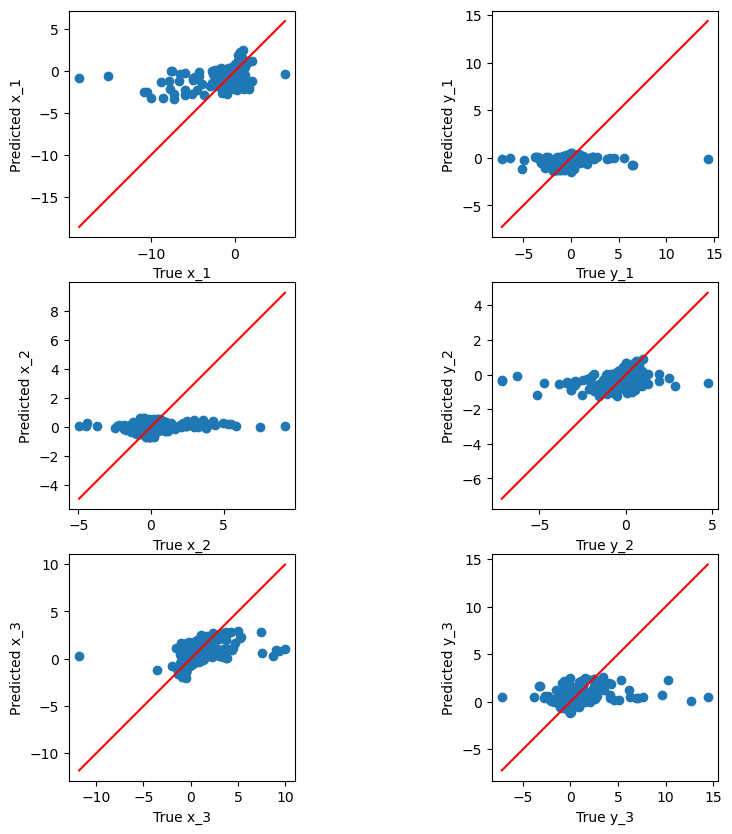

Test RMSE: 1.4302591237255624


In [57]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

### Adding polar coordinates to the features

In [12]:
def calculate_polar_coordinates(x, y):
    # Calculate the radius (r) and angle (theta) in polar coordinates
    r = np.sqrt(x**2 + y**2)
    theta = np.arctan2(y, x)  # Use arctan2 to get the correct angle in all quadrants
    return r, theta

In [58]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
        X_chunk_df['dist_12'] = np.sqrt((X_chunk_df['x_2'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_2'] - X_chunk_df['y_1'])**2)
        X_chunk_df['dist_23'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_2'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_2'])**2)
        X_chunk_df['dist_13'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_1'])**2)
        
        # Calculate the angles between the points
        X_chunk_df['angle_1'] = calculate_angle(X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_2'] = calculate_angle(X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_3'] = calculate_angle(X_chunk_df['x_3'], X_chunk_df['y_3'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'])
        
        # Calculate polar coordinates for each point
        X_chunk_df['r_1'], X_chunk_df['theta_1'] = calculate_polar_coordinates(X_chunk_df['x_1'], X_chunk_df['y_1'])
        X_chunk_df['r_2'], X_chunk_df['theta_2'] = calculate_polar_coordinates(X_chunk_df['x_2'], X_chunk_df['y_2'])
        X_chunk_df['r_3'], X_chunk_df['theta_3'] = calculate_polar_coordinates(X_chunk_df['x_3'], X_chunk_df['y_3'])
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        y_chunk_df['dist_12'] = np.sqrt((y_chunk_df['x_2'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_2'] - y_chunk_df['y_1'])**2)
        y_chunk_df['dist_23'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_2'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_2'])**2)
        y_chunk_df['dist_13'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_1'])**2)
        
        # Calculate angles for targets
        y_chunk_df['angle_1'] = calculate_angle(y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_2'] = calculate_angle(y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_3'] = calculate_angle(y_chunk_df['x_3'], y_chunk_df['y_3'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'])
        
        # Calculate polar coordinates for the targets
        y_chunk_df['r_1'], y_chunk_df['theta_1'] = calculate_polar_coordinates(y_chunk_df['x_1'], y_chunk_df['y_1'])
        y_chunk_df['r_2'], y_chunk_df['theta_2'] = calculate_polar_coordinates(y_chunk_df['x_2'], y_chunk_df['y_2'])
        y_chunk_df['r_3'], y_chunk_df['theta_3'] = calculate_polar_coordinates(y_chunk_df['x_3'], y_chunk_df['y_3'])
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

In [59]:
X_chunks, y_chunks = create_features_and_targets(subframes, 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [62]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

          t  x_1  y_1       x_2       y_2       x_3       y_3   dist_12  \
0  0.000000  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
1  0.039062  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
2  0.078125  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
3  0.117188  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
4  0.156250  1.0  0.0 -0.264968  0.411689 -0.735032 -0.411689  1.330275   

    dist_23   dist_13   angle_1   angle_2  angle_3  r_1  theta_1       r_2  \
0  0.948108  1.783206  0.547614  1.774899  0.81908  1.0      0.0  0.489587   
1  0.948108  1.783206  0.547614  1.774899  0.81908  1.0      0.0  0.489587   
2  0.948108  1.783206  0.547614  1.774899  0.81908  1.0      0.0  0.489587   
3  0.948108  1.783206  0.547614  1.774899  0.81908  1.0      0.0  0.489587   
4  0.948108  1.783206  0.547614  1.774899  0.81908  1.0      0.0  0.489587   

    theta_2       r_3   theta_3  
0  2.142669  0.842472 -2.631031  
1  2.142669 

In [63]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [64]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

In [65]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 2, 3, 4, 5]]
y_test_positions = y_test_df[position_columns].values

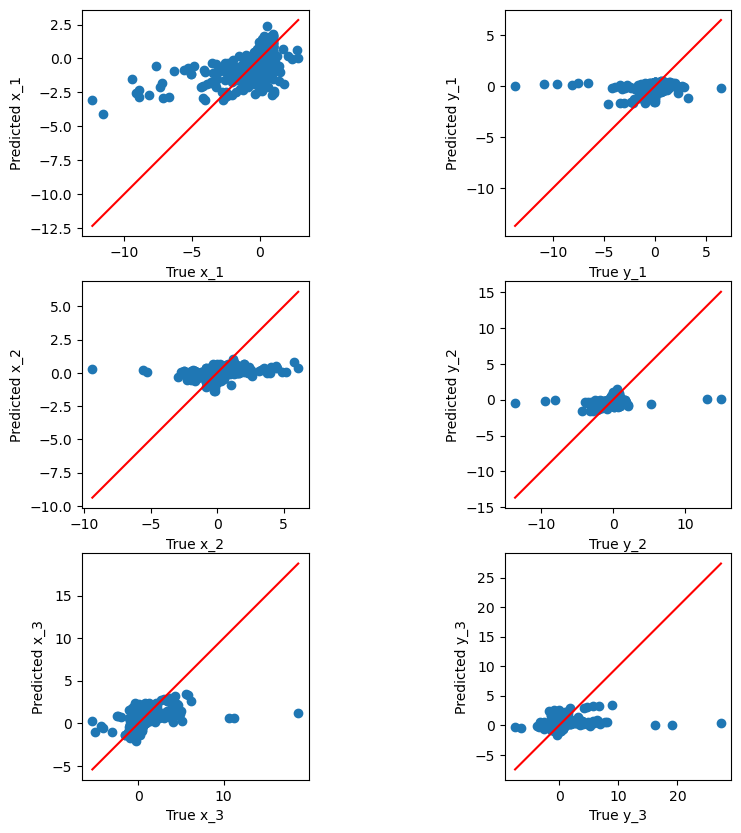

Validation RMSE: 1.33180821643741


In [66]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

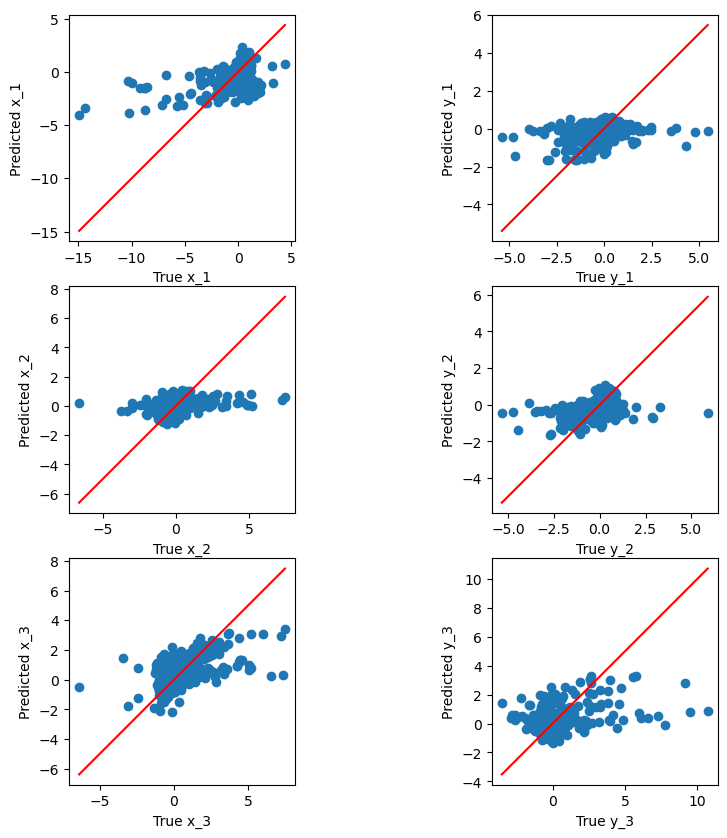

Test RMSE: 1.4066463298162788


In [67]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

### With added features of euclidian distance, angles, polar coordinates. Without y_3 and x_1

In [66]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
        X_chunk_df['dist_12'] = np.sqrt((X_chunk_df['x_2'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_2'] - X_chunk_df['y_1'])**2)
        X_chunk_df['dist_23'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_2'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_2'])**2)
        X_chunk_df['dist_13'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_1'])**2)
        
        # Calculate the angles between the points
        X_chunk_df['angle_1'] = calculate_angle(X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_2'] = calculate_angle(X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_3'] = calculate_angle(X_chunk_df['x_3'], X_chunk_df['y_3'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'])
        
        # Calculate polar coordinates for each point
        X_chunk_df['r_1'], X_chunk_df['theta_1'] = calculate_polar_coordinates(X_chunk_df['x_1'], X_chunk_df['y_1'])
        X_chunk_df['r_2'], X_chunk_df['theta_2'] = calculate_polar_coordinates(X_chunk_df['x_2'], X_chunk_df['y_2'])
        X_chunk_df['r_3'], X_chunk_df['theta_3'] = calculate_polar_coordinates(X_chunk_df['x_3'], X_chunk_df['y_3'])
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        y_chunk_df['dist_12'] = np.sqrt((y_chunk_df['x_2'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_2'] - y_chunk_df['y_1'])**2)
        y_chunk_df['dist_23'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_2'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_2'])**2)
        y_chunk_df['dist_13'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_1'])**2)
        
        # Calculate angles for targets
        y_chunk_df['angle_1'] = calculate_angle(y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_2'] = calculate_angle(y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_3'] = calculate_angle(y_chunk_df['x_3'], y_chunk_df['y_3'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'])
        
        # Calculate polar coordinates for the targets
        y_chunk_df['r_1'], y_chunk_df['theta_1'] = calculate_polar_coordinates(y_chunk_df['x_1'], y_chunk_df['y_1'])
        y_chunk_df['r_2'], y_chunk_df['theta_2'] = calculate_polar_coordinates(y_chunk_df['x_2'], y_chunk_df['y_2'])
        y_chunk_df['r_3'], y_chunk_df['theta_3'] = calculate_polar_coordinates(y_chunk_df['x_3'], y_chunk_df['y_3'])
        
        # Drop the 'x_1' and 'y_3' columns
        X_chunk_df = X_chunk_df.drop(columns=['x_1', 'y_3'])
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

In [67]:
X_chunks, y_chunks = create_features_and_targets(subframes, 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [68]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

print(X_train[0].head())
print(y_train[0].head())

          t  y_1       x_2       y_2       x_3   dist_12   dist_23   dist_13  \
0  0.000000  0.0 -0.264968  0.411689 -0.735032  1.330275  0.948108  1.783206   
1  0.039062  0.0 -0.264968  0.411689 -0.735032  1.330275  0.948108  1.783206   
2  0.078125  0.0 -0.264968  0.411689 -0.735032  1.330275  0.948108  1.783206   
3  0.117188  0.0 -0.264968  0.411689 -0.735032  1.330275  0.948108  1.783206   
4  0.156250  0.0 -0.264968  0.411689 -0.735032  1.330275  0.948108  1.783206   

    angle_1   angle_2  angle_3  r_1  theta_1       r_2   theta_2       r_3  \
0  0.547614  1.774899  0.81908  1.0      0.0  0.489587  2.142669  0.842472   
1  0.547614  1.774899  0.81908  1.0      0.0  0.489587  2.142669  0.842472   
2  0.547614  1.774899  0.81908  1.0      0.0  0.489587  2.142669  0.842472   
3  0.547614  1.774899  0.81908  1.0      0.0  0.489587  2.142669  0.842472   
4  0.547614  1.774899  0.81908  1.0      0.0  0.489587  2.142669  0.842472   

    theta_3  
0 -2.631031  
1 -2.631031  
2 -2.631

In [69]:
X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [17]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

In [18]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 2, 3, 4, 5]]
y_test_positions = y_test_df[position_columns].values

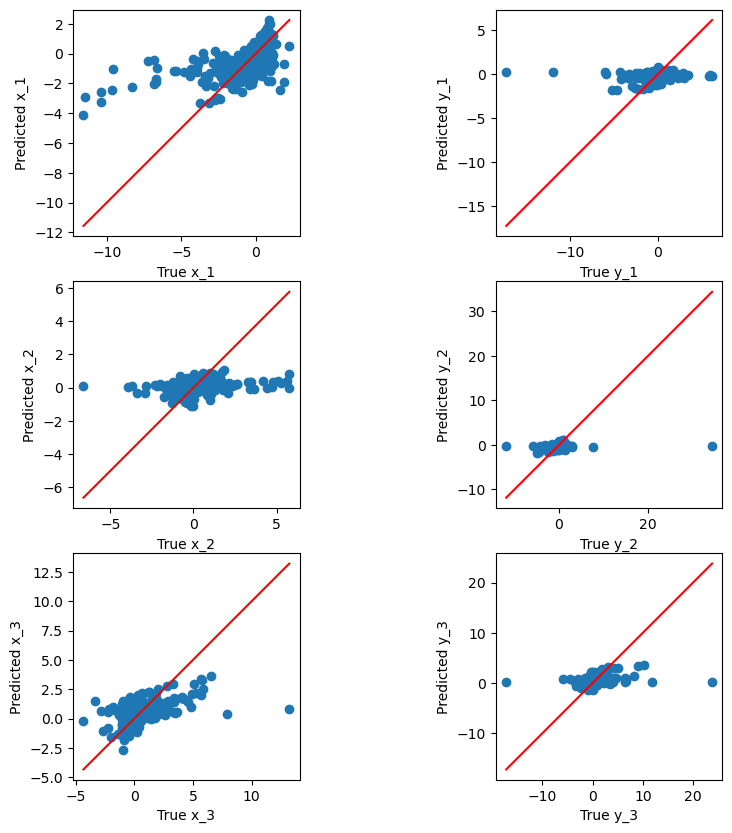

Validation RMSE: 1.3318126370583252


In [21]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

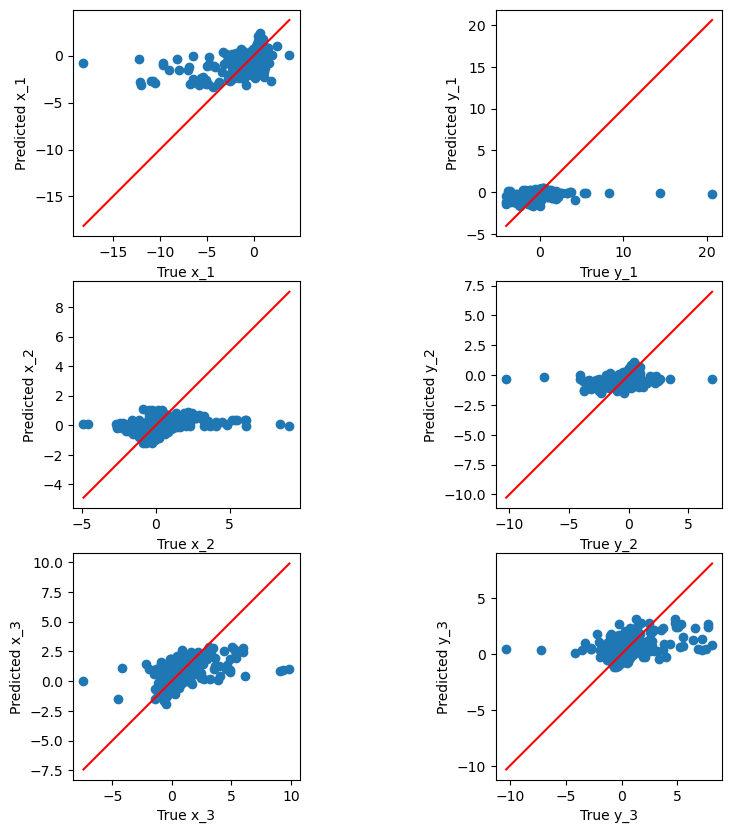

Test RMSE: 1.406658427413449


In [22]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

## Task 3.4 Evaluation of Variable Augmentation

In [23]:
def validate_poly_regression(X_train, y_train, X_val, y_val, regressor=None, degrees=range(1, 9), max_features=None):
    best_rmse = np.inf
    best_model = None
    best_degree = None

    for degree in degrees:
        
        poly = PolynomialFeatures(degree, include_bias=False)
        
        # Default to Linear Regression if no regressor is specified
        if regressor is None:
            polyreg = make_pipeline(StandardScaler(), poly, LinearRegression())
        else:
            polyreg = make_pipeline(StandardScaler(), poly, regressor)
            
        polyreg.fit(X_train, y_train)
        
        n_features = poly.n_output_features_
        
        # Abort if number of features exceeds the limit
        if max_features is not None and n_features > max_features:
            break
            
        y_pred = polyreg.predict(X_val)
        
        position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

        y_val_positions = y_val[position_columns].values
        y_pred_positions = y_pred[:, [0, 1, 2, 3, 4, 5]] 
        
        rmse = root_mean_squared_error(y_val_positions, y_pred_positions)
        
        print(f"Degree {degree}: {n_features} features | RMSE: {rmse}")
        
        if rmse < best_rmse:
            best_rmse = rmse
            best_model = polyreg
            best_degree = degree
            
    print(f"Best Degree: {best_degree}, RMSE: {best_rmse}")
    
    return best_model, best_degree, best_rmse


Degree 1: 17 features | RMSE: 1.3290640946194412
Degree 2: 170 features | RMSE: 1.2726730413698502
Degree 3: 1139 features | RMSE: 1.2360620210099473
Degree 4: 5984 features | RMSE: 1.209481566500947
Best Degree: 4, RMSE: 1.209481566500947


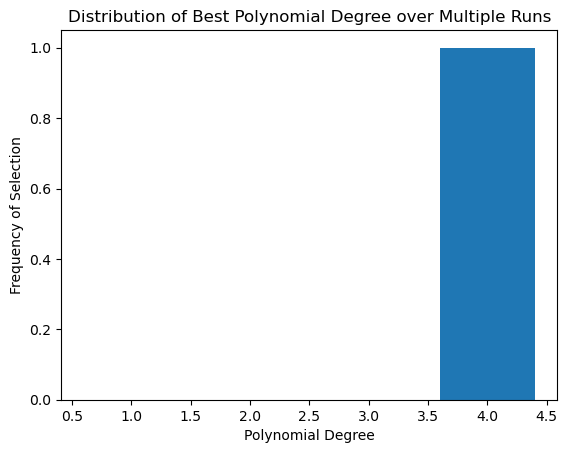

In [137]:
degree_counts = {degree: 0 for degree in range(1,5)}

for run in range(1):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, regressor = RidgeCV(), degrees=range(1, 5))
    
    # Track the best degree for this run
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()


In [70]:
degree = 3

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

In [71]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 2, 3, 4, 5]]
y_test_positions = y_test_df[position_columns].values

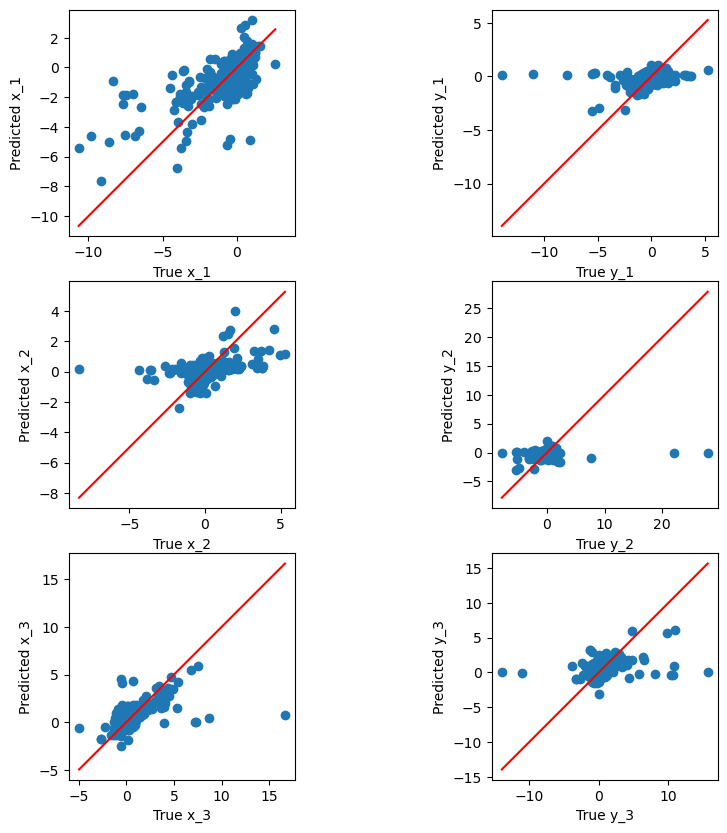

Validation RMSE: 1.2242282106565119


In [72]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

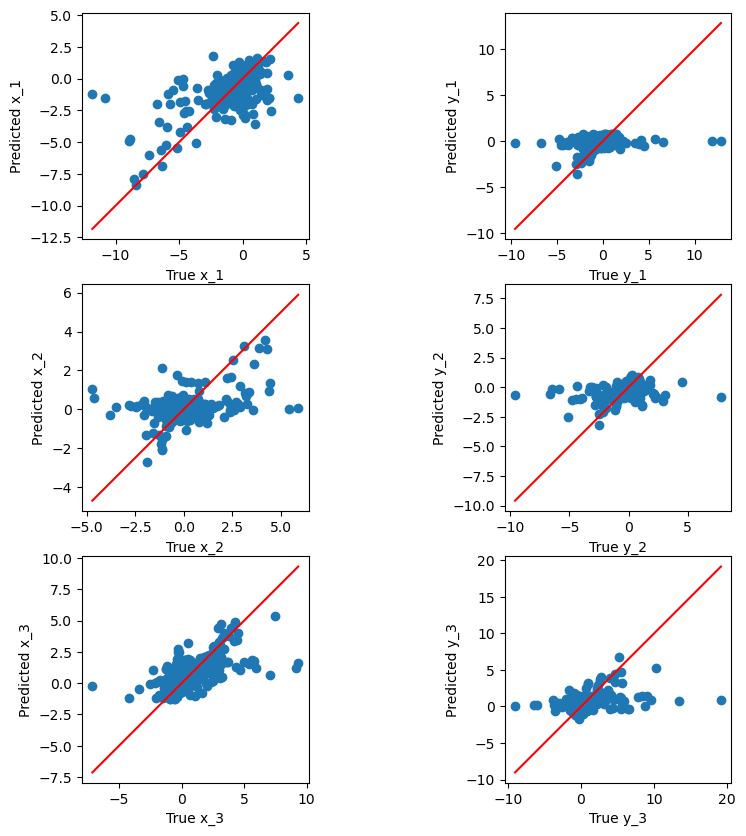

Test RMSE: 1.2792770971731062


In [73]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

In [74]:
X_kaggle_df_augmented = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df_augmented.drop(columns=['Id'], inplace=True)

# Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
X_kaggle_df_augmented['dist_12'] = np.sqrt((X_kaggle_df_augmented['x_2'] - X_kaggle_df_augmented['x_1'])**2 + (X_kaggle_df_augmented['y_2'] - X_kaggle_df_augmented['y_1'])**2)
X_kaggle_df_augmented['dist_23'] = np.sqrt((X_kaggle_df_augmented['x_3'] - X_kaggle_df_augmented['x_2'])**2 + (X_kaggle_df_augmented['y_3'] - X_kaggle_df_augmented['y_2'])**2)
X_kaggle_df_augmented['dist_13'] = np.sqrt((X_kaggle_df_augmented['x_3'] - X_kaggle_df_augmented['x_1'])**2 + (X_kaggle_df_augmented['y_3'] - X_kaggle_df_augmented['y_1'])**2)

# Calculate the angles between the points
X_kaggle_df_augmented['angle_1'] = calculate_angle(X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'], X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'], X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'])
X_kaggle_df_augmented['angle_2'] = calculate_angle(X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'], X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'], X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'])
X_kaggle_df_augmented['angle_3'] = calculate_angle(X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'], X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'], X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'])

# Calculate polar coordinates for each point
X_kaggle_df_augmented['r_1'], X_kaggle_df_augmented['theta_1'] = calculate_polar_coordinates(X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'])
X_kaggle_df_augmented['r_2'], X_kaggle_df_augmented['theta_2'] = calculate_polar_coordinates(X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'])
X_kaggle_df_augmented['r_3'], X_kaggle_df_augmented['theta_3'] = calculate_polar_coordinates(X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'])

X_kaggle_df_augmented = X_kaggle_df_augmented.drop(columns=['x_1', 'y_3'])
X_kaggle_df_augmented.head()

,t,y_1,x_2,y_2,x_3,dist_12,dist_23,dist_13,angle_1,angle_2,angle_3,r_1,theta_1,r_2,theta_2,r_3,theta_3
0,0.000000,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.0,0.751855,1.812027,1.098204,-2.414368
1,0.039062,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.0,0.751855,1.812027,1.098204,-2.414368
2,0.078125,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.0,0.751855,1.812027,1.098204,-2.414368
3,0.117188,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.0,0.751855,1.812027,1.098204,-2.414368
4,0.156250,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.0,0.751855,1.812027,1.098204,-2.414368


In [75]:
y_augmented_polynomial_pred = polyreg.predict(X_kaggle_df_augmented)

In [76]:
def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'theta_1', 'r_2', 'theta_2', 'r_3', 'theta_3'])
    
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions['Id'] = df_positions.index
    
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions.to_csv(path, index=False)

In [77]:
save_predictions(y_augmented_polynomial_pred, '../submissions/augmented_polynomial_submission.csv')

C:\Users\rasvi\AppData\Local\Temp\ipykernel_10656\2632062796.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_positions['Id'] = df_positions.index


In [78]:
print(type(polyreg))
initial_type = [('float_input', FloatTensorType([None, X_kaggle_df_augmented.shape[1]]))]  

# Convert the model to ONNX format
onnx_model = convert_sklearn(polyreg, initial_types=initial_type)

# Save the ONNX model to a file
with open("augmented_polynomial-model.onnx", "wb") as f:
    f.write(onnx_model.SerializeToString())

<class 'sklearn.pipeline.Pipeline'>


# Additional features: Euclidian distances, angles, vector length

In [28]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
        X_chunk_df['dist_12'] = np.sqrt((X_chunk_df['x_2'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_2'] - X_chunk_df['y_1'])**2)
        X_chunk_df['dist_23'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_2'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_2'])**2)
        X_chunk_df['dist_13'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_1'])**2)
        
        # Calculate the angles between the points
        X_chunk_df['angle_1'] = calculate_angle(X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_2'] = calculate_angle(X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_3'] = calculate_angle(X_chunk_df['x_3'], X_chunk_df['y_3'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'])
        
        # Calculate polar coordinates for each point
        X_chunk_df['r_1'], _ = calculate_polar_coordinates(X_chunk_df['x_1'], X_chunk_df['y_1'])
        X_chunk_df['r_2'], _ = calculate_polar_coordinates(X_chunk_df['x_2'], X_chunk_df['y_2'])
        X_chunk_df['r_3'], _ = calculate_polar_coordinates(X_chunk_df['x_3'], X_chunk_df['y_3'])
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        y_chunk_df['dist_12'] = np.sqrt((y_chunk_df['x_2'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_2'] - y_chunk_df['y_1'])**2)
        y_chunk_df['dist_23'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_2'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_2'])**2)
        y_chunk_df['dist_13'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_1'])**2)
        
        # Calculate angles for targets
        y_chunk_df['angle_1'] = calculate_angle(y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_2'] = calculate_angle(y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_3'] = calculate_angle(y_chunk_df['x_3'], y_chunk_df['y_3'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'])
        
        # Calculate polar coordinates for the targets
        y_chunk_df['r_1'], _ = calculate_polar_coordinates(y_chunk_df['x_1'], y_chunk_df['y_1'])
        y_chunk_df['r_2'], _ = calculate_polar_coordinates(y_chunk_df['x_2'], y_chunk_df['y_2'])
        y_chunk_df['r_3'], _ = calculate_polar_coordinates(y_chunk_df['x_3'], y_chunk_df['y_3'])
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

In [29]:
X_chunks, y_chunks = create_features_and_targets(subframes, 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [30]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [35]:
X_train_df.head()

,t,x_1,y_1,x_2,y_2,x_3,y_3,dist_12,dist_23,dist_13,angle_1,angle_2,angle_3,r_1,r_2,r_3
0,0.000000,1.0,0.0,-0.264968,0.411689,-0.735032,-0.411689,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
1,0.039062,1.0,0.0,-0.264968,0.411689,-0.735032,-0.411689,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
2,0.078125,1.0,0.0,-0.264968,0.411689,-0.735032,-0.411689,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
3,0.117188,1.0,0.0,-0.264968,0.411689,-0.735032,-0.411689,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
4,0.156250,1.0,0.0,-0.264968,0.411689,-0.735032,-0.411689,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472


In [62]:
print(y_train_df.head())

             x_1       y_1       x_2       y_2       x_3       y_3   dist_12  \
446923  1.000000  0.000000 -0.264968  0.411689 -0.735032 -0.411689  1.330275   
446924  0.999356  0.000078 -0.264979  0.410818 -0.734377 -0.410896  1.329380   
446925  0.997424  0.000312 -0.265015  0.408199 -0.732409 -0.408511  1.326696   
446926  0.994196  0.000701 -0.265082  0.403818 -0.729114 -0.404520  1.322226   
446927  0.989662  0.001245 -0.265192  0.397647 -0.724470 -0.398892  1.315976   

         dist_23   dist_13   angle_1   angle_2   angle_3       r_1       r_2  \
446923  0.948108  1.783206  0.547614  1.774899  0.819080  1.000000  0.489587   
446924  0.946333  1.781777  0.546860  1.775692  0.819041  0.999356  0.488861   
446925  0.940996  1.777486  0.544586  1.778082  0.818924  0.997424  0.486682   
446926  0.932060  1.770311  0.540755  1.782112  0.818725  0.994196  0.483050   
446927  0.919462  1.760215  0.535302  1.787852  0.818439  0.989663  0.477964   

             r_3  
446923  0.842472  


In [31]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

In [32]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 2, 3, 4, 5]]
y_test_positions = y_test_df[position_columns].values

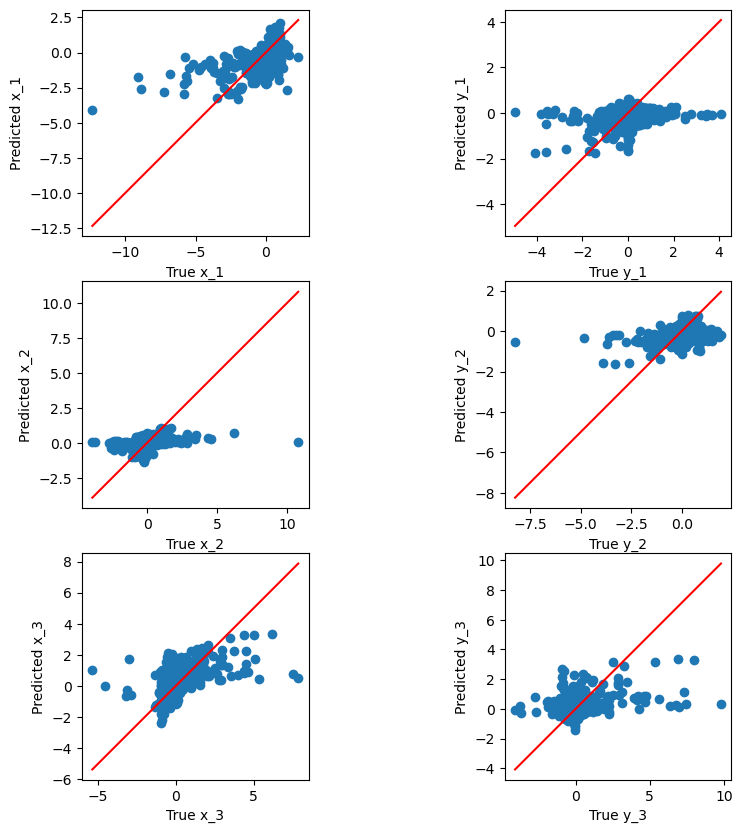

Validation RMSE: 1.3376411856774222


In [33]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

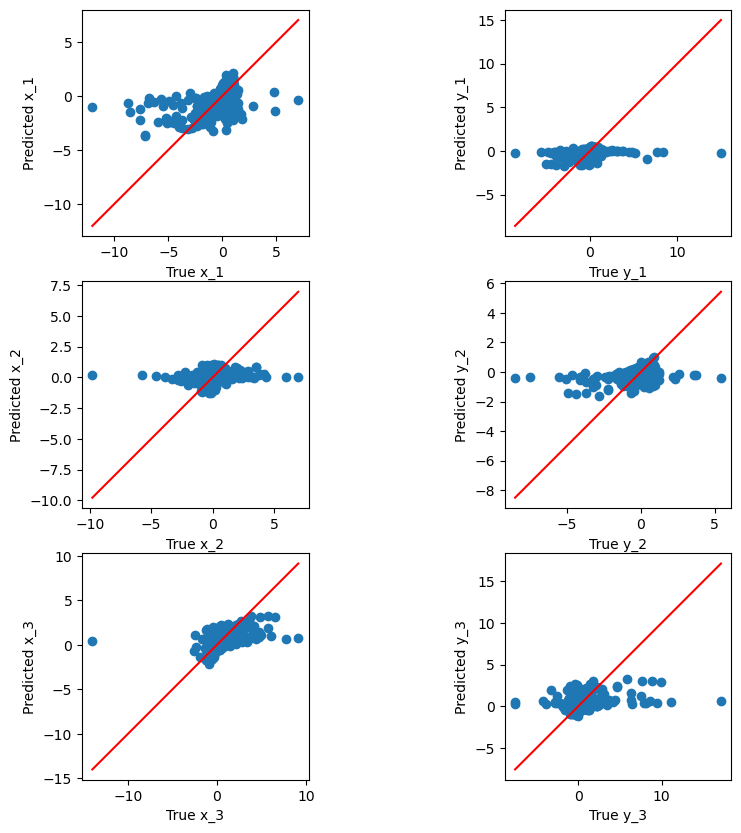

Test RMSE: 1.4163847793514437


In [34]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

No x_1 and y_3

In [42]:
def create_features_and_targets(cleaned_subframes, feature_labels, target_labels):
    X_chunks = []
    y_chunks = []
    
    for df in cleaned_subframes:
        if df.empty:
            continue
        
        # Get initial conditions as numpy array
        initial_conditions = df.iloc[0][feature_labels].values
        
        # Use vectorized operations to create features
        time_values = df['t'].values
        initial_conditions_repeated = np.tile(initial_conditions, (len(df), 1))  # Repeat initial conditions for all rows
        X_chunk = np.column_stack((time_values, initial_conditions_repeated))  # Combine time with initial conditions
        
        # Convert to DataFrame
        X_chunk_df = pd.DataFrame(X_chunk, columns=['t'] + feature_labels)
        
        # Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
        X_chunk_df['dist_12'] = np.sqrt((X_chunk_df['x_2'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_2'] - X_chunk_df['y_1'])**2)
        X_chunk_df['dist_23'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_2'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_2'])**2)
        X_chunk_df['dist_13'] = np.sqrt((X_chunk_df['x_3'] - X_chunk_df['x_1'])**2 + (X_chunk_df['y_3'] - X_chunk_df['y_1'])**2)
        
        # Calculate the angles between the points
        X_chunk_df['angle_1'] = calculate_angle(X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_2'] = calculate_angle(X_chunk_df['x_2'], X_chunk_df['y_2'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_3'], X_chunk_df['y_3'])
        X_chunk_df['angle_3'] = calculate_angle(X_chunk_df['x_3'], X_chunk_df['y_3'], X_chunk_df['x_1'], X_chunk_df['y_1'], X_chunk_df['x_2'], X_chunk_df['y_2'])
        
        # Calculate polar coordinates for each point
        X_chunk_df['r_1'], _ = calculate_polar_coordinates(X_chunk_df['x_1'], X_chunk_df['y_1'])
        X_chunk_df['r_2'], _ = calculate_polar_coordinates(X_chunk_df['x_2'], X_chunk_df['y_2'])
        X_chunk_df['r_3'], _ = calculate_polar_coordinates(X_chunk_df['x_3'], X_chunk_df['y_3'])
        
        # Extract targets using vectorized operations
        y_chunk_df = df[target_labels].copy()  # Directly slice the target columns from the dataframe
        
        y_chunk_df['dist_12'] = np.sqrt((y_chunk_df['x_2'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_2'] - y_chunk_df['y_1'])**2)
        y_chunk_df['dist_23'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_2'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_2'])**2)
        y_chunk_df['dist_13'] = np.sqrt((y_chunk_df['x_3'] - y_chunk_df['x_1'])**2 + (y_chunk_df['y_3'] - y_chunk_df['y_1'])**2)
        
        # Calculate angles for targets
        y_chunk_df['angle_1'] = calculate_angle(y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_2'] = calculate_angle(y_chunk_df['x_2'], y_chunk_df['y_2'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_3'], y_chunk_df['y_3'])
        y_chunk_df['angle_3'] = calculate_angle(y_chunk_df['x_3'], y_chunk_df['y_3'], y_chunk_df['x_1'], y_chunk_df['y_1'], y_chunk_df['x_2'], y_chunk_df['y_2'])
        
        # Calculate polar coordinates for the targets
        y_chunk_df['r_1'], _ = calculate_polar_coordinates(y_chunk_df['x_1'], y_chunk_df['y_1'])
        y_chunk_df['r_2'], _ = calculate_polar_coordinates(y_chunk_df['x_2'], y_chunk_df['y_2'])
        y_chunk_df['r_3'], _ = calculate_polar_coordinates(y_chunk_df['x_3'], y_chunk_df['y_3'])
        
        # Drop the 'x_1' and 'y_3' columns
        X_chunk_df = X_chunk_df.drop(columns=['x_1', 'y_3'])
        
        # Append the dataframes for each scenario to the chunks list
        X_chunks.append(X_chunk_df)
        y_chunks.append(y_chunk_df)
    
    return X_chunks, y_chunks

In [43]:
X_chunks, y_chunks = create_features_and_targets(subframes, 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'], 
                                                 ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3'])

In [44]:
X_train, X_dev, y_train, y_dev = train_test_split(X_chunks, y_chunks, test_size=0.2, random_state=42)
X_dev, X_test, y_dev, y_test = train_test_split(X_dev, y_dev, test_size=0.5, random_state=42)

X_train_df = pd.concat(X_train, axis=0)
y_train_df = pd.concat(y_train, axis=0)

X_dev_df = pd.concat(X_dev, axis=0)
y_dev_df = pd.concat(y_dev, axis=0)

X_test_df = pd.concat(X_test, axis=0)
y_test_df = pd.concat(y_test, axis=0)

In [45]:
X_train_df.head()

,t,y_1,x_2,y_2,x_3,dist_12,dist_23,dist_13,angle_1,angle_2,angle_3,r_1,r_2,r_3
0,0.000000,0.0,-0.264968,0.411689,-0.735032,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
1,0.039062,0.0,-0.264968,0.411689,-0.735032,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
2,0.078125,0.0,-0.264968,0.411689,-0.735032,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
3,0.117188,0.0,-0.264968,0.411689,-0.735032,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472
4,0.156250,0.0,-0.264968,0.411689,-0.735032,1.330275,0.948108,1.783206,0.547614,1.774899,0.81908,1.0,0.489587,0.842472


In [46]:
y_train_df.head()

,x_1,y_1,x_2,y_2,x_3,y_3,dist_12,dist_23,dist_13,angle_1,angle_2,angle_3,r_1,r_2,r_3
446923,1.000000,0.000000,-0.264968,0.411689,-0.735032,-0.411689,1.330275,0.948108,1.783206,0.547614,1.774899,0.819080,1.000000,0.489587,0.842472
446924,0.999356,0.000078,-0.264979,0.410818,-0.734377,-0.410896,1.329380,0.946333,1.781777,0.546860,1.775692,0.819041,0.999356,0.488861,0.841513
446925,0.997424,0.000312,-0.265015,0.408199,-0.732409,-0.408511,1.326696,0.940996,1.777486,0.544586,1.778082,0.818924,0.997424,0.486682,0.838632
446926,0.994196,0.000701,-0.265082,0.403818,-0.729114,-0.404520,1.322226,0.932060,1.770311,0.540755,1.782112,0.818725,0.994196,0.483050,0.833812
446927,0.989662,0.001245,-0.265192,0.397647,-0.724470,-0.398892,1.315976,0.919462,1.760215,0.535302,1.787852,0.818439,0.989663,0.477964,0.827026


In [47]:
polyreg=make_pipeline(StandardScaler(),
                      LinearRegression())

polyreg.fit(X_train_df, y_train_df)

y_dev_pred = polyreg.predict(X_dev_df)

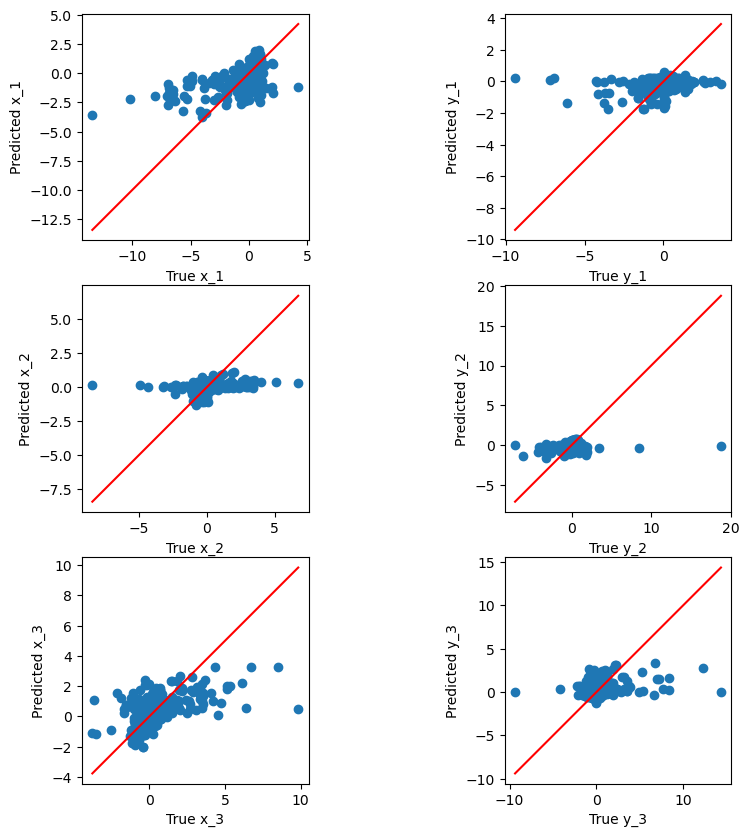

Validation RMSE: 1.3376411856774222


In [48]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

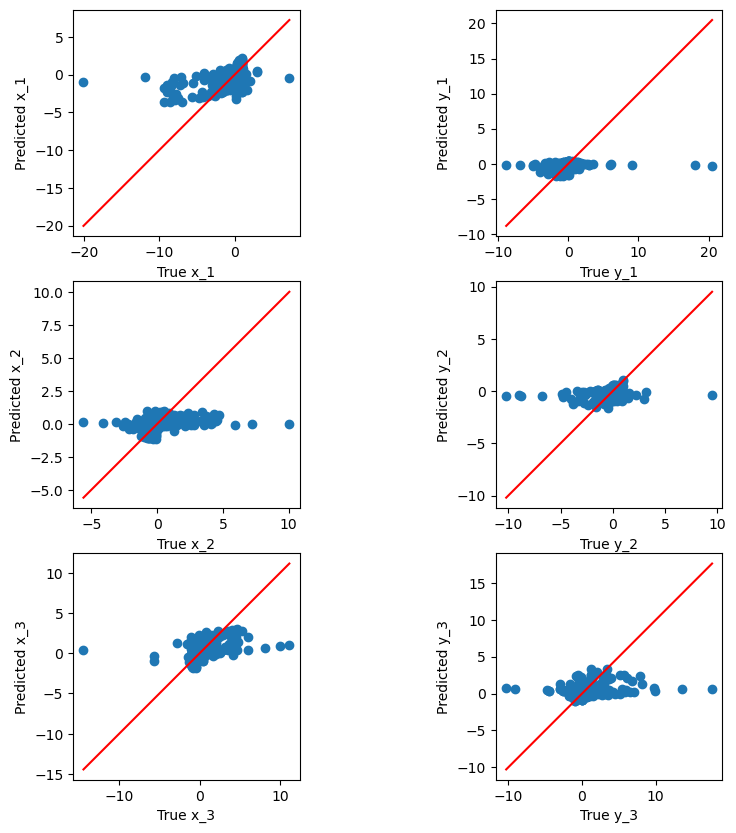

Test RMSE: 1.416400567740151


In [49]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

Degree 1: 14 features | RMSE: 1.3392984490433628
Degree 2: 119 features | RMSE: 1.2829068069767384
Degree 3: 679 features | RMSE: 1.2528974607948424
Degree 4: 3059 features | RMSE: 1.2313201587049052
Degree 5: 11627 features | RMSE: 1.2247851169815913
Best Degree: 5, RMSE: 1.2247851169815913


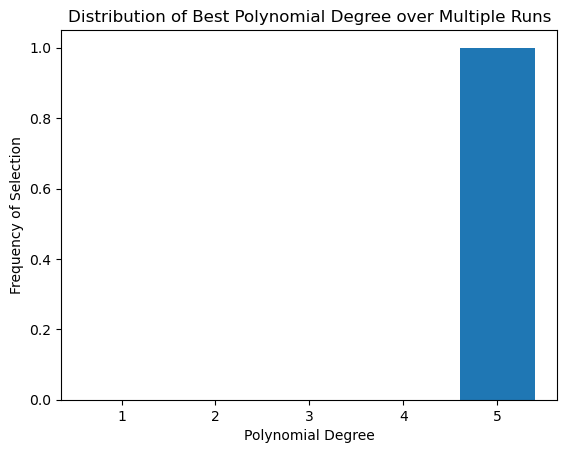

In [51]:
degree_counts = {degree: 0 for degree in range(1,6)}

for run in range(1):
    X_train_sample, y_train_sample = resample(X_train_df, y_train_df, n_samples=int(0.01 * len(X_train_df)))
    model, degree, rmse = validate_poly_regression(X_train_sample, y_train_sample, X_dev_df, y_dev_df, regressor = RidgeCV(), degrees=range(1, 6))
    
    # Track the best degree for this run
    degree_counts[degree] += 1
  
plt.bar(degree_counts.keys(), degree_counts.values())
plt.xlabel('Polynomial Degree')
plt.ylabel('Frequency of Selection')
plt.title('Distribution of Best Polynomial Degree over Multiple Runs')
plt.show()


In [55]:
degree = 3

polyreg=make_pipeline(StandardScaler(), PolynomialFeatures(degree, include_bias=False),
                      RidgeCV())

# Fit the model
polyreg.fit(X_train_df, y_train_df)

# Predict the targets for the validation set
y_dev_pred = polyreg.predict(X_dev_df)

In [56]:
position_columns = ['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']

y_dev_positions = y_dev_df[position_columns].values
y_pred_positions = y_dev_pred[:, [0, 1, 2, 3, 4, 5]]
y_test_positions = y_test_df[position_columns].values

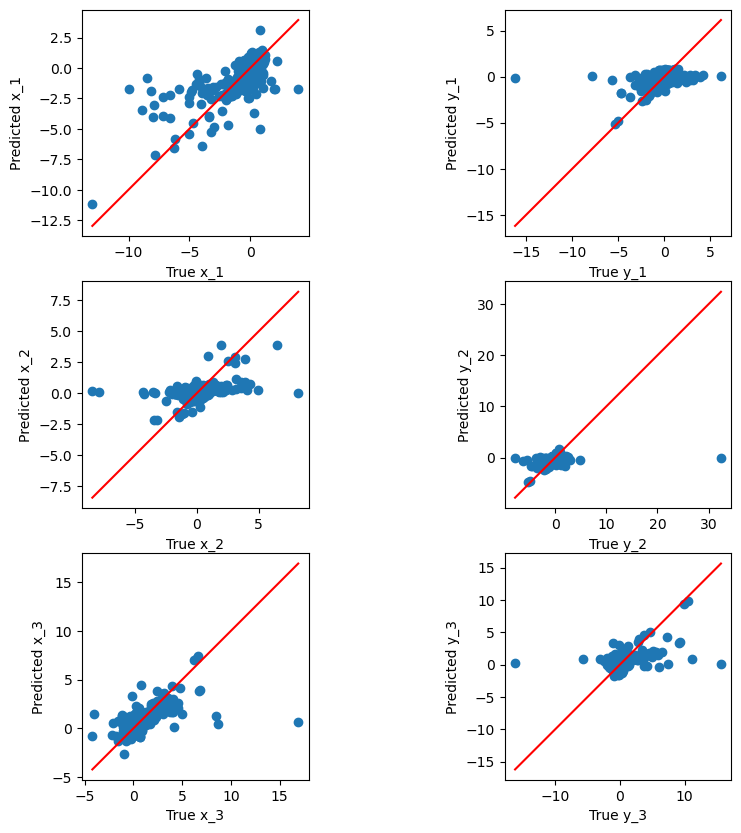

Validation RMSE: 1.2295735630206839


In [57]:
plot_y_yhat(y_dev_positions, y_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_dev_positions, y_pred_positions)

print(f"Validation RMSE: {rmse}")

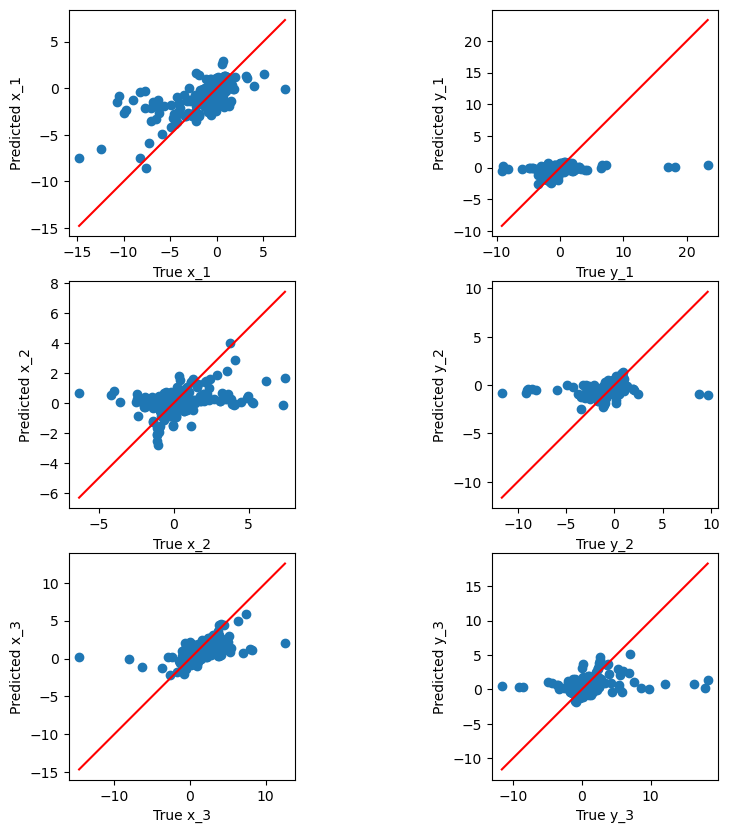

Test RMSE: 1.2847526746987004


In [58]:
y_test_pred = polyreg.predict(X_test_df)
y_test_pred_positions = y_test_pred[:, [0, 1, 2, 3, 4, 5]]

plot_y_yhat(y_test_positions, y_test_pred_positions, plot_title="y_yhat_plot")

rmse = root_mean_squared_error(y_test_positions, y_test_pred_positions)

print(f"Test RMSE: {rmse}")

In [60]:
X_kaggle_df_augmented = pd.read_csv('../mlNOVA/X_test.csv')
X_kaggle_df_augmented.drop(columns=['Id'], inplace=True)

# Calculate Euclidean distances between points (x_1, y_1), (x_2, y_2), and (x_3, y_3)
X_kaggle_df_augmented['dist_12'] = np.sqrt((X_kaggle_df_augmented['x_2'] - X_kaggle_df_augmented['x_1'])**2 + (X_kaggle_df_augmented['y_2'] - X_kaggle_df_augmented['y_1'])**2)
X_kaggle_df_augmented['dist_23'] = np.sqrt((X_kaggle_df_augmented['x_3'] - X_kaggle_df_augmented['x_2'])**2 + (X_kaggle_df_augmented['y_3'] - X_kaggle_df_augmented['y_2'])**2)
X_kaggle_df_augmented['dist_13'] = np.sqrt((X_kaggle_df_augmented['x_3'] - X_kaggle_df_augmented['x_1'])**2 + (X_kaggle_df_augmented['y_3'] - X_kaggle_df_augmented['y_1'])**2)

# Calculate the angles between the points
X_kaggle_df_augmented['angle_1'] = calculate_angle(X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'], X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'], X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'])
X_kaggle_df_augmented['angle_2'] = calculate_angle(X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'], X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'], X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'])
X_kaggle_df_augmented['angle_3'] = calculate_angle(X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'], X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'], X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'])

# Calculate polar coordinates for each point
X_kaggle_df_augmented['r_1'], _ = calculate_polar_coordinates(X_kaggle_df_augmented['x_1'], X_kaggle_df_augmented['y_1'])
X_kaggle_df_augmented['r_2'], _ = calculate_polar_coordinates(X_kaggle_df_augmented['x_2'], X_kaggle_df_augmented['y_2'])
X_kaggle_df_augmented['r_3'], _ = calculate_polar_coordinates(X_kaggle_df_augmented['x_3'], X_kaggle_df_augmented['y_3'])

X_kaggle_df_augmented = X_kaggle_df_augmented.drop(columns=['x_1', 'y_3'])
X_kaggle_df_augmented.head()

,t,y_1,x_2,y_2,x_3,dist_12,dist_23,dist_13,angle_1,angle_2,angle_3,r_1,r_2,r_3
0,0.000000,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.751855,1.098204
1,0.039062,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.751855,1.098204
2,0.078125,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.751855,1.098204
3,0.117188,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.751855,1.098204
4,0.156250,0.0,-0.179617,0.730085,-0.820383,1.387271,1.594578,1.961331,0.935634,1.43011,0.775849,1.0,0.751855,1.098204


In [63]:
y_augmented_polynomial_pred = polyreg.predict(X_kaggle_df_augmented)

In [64]:
def save_predictions(predictions, path):
    df = pd.DataFrame(predictions, columns=['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3', 'dist_12', 'dist_23', 'dist_13', 'angle_1', 'angle_2', 'angle_3', 'r_1', 'r_2', 'r_3'])
    
    df_positions = df[['x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions['Id'] = df_positions.index
    
    df_positions = df_positions[['Id', 'x_1', 'y_1', 'x_2', 'y_2', 'x_3', 'y_3']]
    
    df_positions.to_csv(path, index=False)

In [65]:
save_predictions(y_augmented_polynomial_pred, '../submissions/augmented_polynomial_submission.csv')

C:\Users\rasvi\AppData\Local\Temp\ipykernel_10656\2612186645.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_positions['Id'] = df_positions.index
